# Designing a Nanoparticle That Dissolves a Blood Clot

### A physics-based design optimizer built from the thrombolysis literature

---

**The one-sentence version:** clot-busting drugs work, but we give them by
flooding the whole bloodstream, and the flooding is what causes the bleeding.
This notebook builds a model of how a drug-carrying particle actually travels
to a clot and sticks to it, checks that model against five published findings
it was never fitted to, and then searches the design space to find the
particle shapes that clear a clot with the smallest dose.

**The result:** the model reproduces all five published findings, and it finds
that the best designs are not the smallest particles. They are roughly
1-2 micrometre, flattened or rod-shaped, relatively stiff particles -- which
is what the experimental papers found, for reasons the model derives from
first principles rather than being told.

---

This notebook is in two parts:

- **Part I — Study guide.** Everything needed to explain this project to
  someone who has never heard of it: what a stroke is, how the drug works,
  why the current treatment is dangerous, and the one idea the whole project
  turns on. Diagrams, a glossary, a 60-second pitch, and the questions a judge
  is likely to ask.
- **Part II — The model.** The actual work: the four-stage delivery model,
  the five validation tests, and the design optimizer.

Part I runs in a couple of seconds and needs nothing from Part II, so it can
be presented on its own.

In [70]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import gridspec
from matplotlib.patches import (Circle, Ellipse, Rectangle, FancyBboxPatch,
                                FancyArrowPatch, Polygon, Wedge)

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160,
    "font.size": 10.5, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.labelsize": 10.5, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
    "legend.frameon": False, "figure.autolayout": False,
})

# one palette, reused everywhere, colour-blind safe
CLR = {"sphere": "#4C78A8", "prolate": "#F58518", "rod": "#54A24B",
       "oblate": "#B279A2", "accent": "#E45756", "grey": "#7F7F7F",
       "soft": "#4C78A8", "rigid": "#E45756",
       "rbc": "#C0392B", "clot": "#4A3728", "vessel": "#D98880",
       "drug": "#2E86C1", "tissue": "#F4ECD8", "dead": "#9E9E9E"}
SHAPE_LABEL = {"sphere": "sphere", "prolate": "prolate (egg)",
               "rod": "rod", "oblate": "oblate (disc)"}


def tidy(ax, title=None, xlabel=None, ylabel=None):
    if title:
        ax.set_title(title, loc="left", pad=8)
    if xlabel:
        ax.set_xlabel(xlabel)
    if ylabel:
        ax.set_ylabel(ylabel)
    return ax


def canvas(ax, xlim=(0, 10), ylim=(0, 6)):
    # a blank drawing surface for the schematic diagrams
    ax.set_xlim(*xlim); ax.set_ylim(*ylim)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)
    return ax


def box(ax, x, y, w, h, text, fc="#F2F4F7", ec="#5A6472", fs=9.2, tc="#1A1A1A",
        lw=1.3, weight="normal"):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.10",
                                facecolor=fc, edgecolor=ec, linewidth=lw))
    ax.text(x + w/2, y + h/2, text, ha="center", va="center", fontsize=fs,
            color=tc, fontweight=weight, linespacing=1.35)


def arrow(ax, p0, p1, color="#5A6472", lw=1.8, style="-|>", rad=0.0):
    ax.add_patch(FancyArrowPatch(p0, p1, arrowstyle=style, mutation_scale=15,
                                 color=color, linewidth=lw,
                                 connectionstyle=f"arc3,rad={rad}"))


def blunt(ax, p0, p1, color="#E45756", lw=2.0):
    # blunt-ended arrow: the symbol for "blocks", not "becomes"
    ax.add_patch(FancyArrowPatch(p0, p1, arrowstyle="|-|,widthA=0,widthB=5",
                                 mutation_scale=1, color=color, linewidth=lw))

---

# Part I — Study guide

### How to explain this project to someone who has never heard of it

Everything in this half is background and framing. No model code runs here,
and none of it depends on Part II — this section can be presented on its own.

## A1. The 60-second version

> Every minute a stroke goes untreated, about **1.9 million brain cells die**.
> The drug we use to dissolve the clot works, but it has to be pumped through
> the entire bloodstream to reach one small blockage, and the drug that does
> not reach the clot can cause dangerous bleeding somewhere else — including
> in the brain.
>
> One way around this is to carry the drug on a tiny particle designed to
> collect at the clot, so a much smaller dose does the same job. But nobody
> can build and test every possible particle: size, shape, stiffness and
> surface coating can each be varied, and they interfere with each other.
>
> So I built a computer model of the physics — how a particle travels to a
> blood vessel wall, sticks to it, survives in the bloodstream, and releases
> its drug — and I checked it against five published experimental findings it
> had never been shown. It reproduced all five. Then I used it to search
> thousands of particle designs.
>
> It found that **the best particles are not the smallest ones.** They are
> flattened, disc-shaped, about a micrometre across — roughly one-hundredth
> the width of a human hair, and about ten times bigger than the nanoparticles
> most people reach for. The model explains why, and the explanation is that
> **red blood cells do the steering.**

If you remember one sentence, make it the last one.

## A2. The problem — what a stroke actually is

An **ischemic stroke** happens when a clot plugs an artery feeding the brain.
Everything downstream stops getting oxygen. The cells in the very centre die
almost immediately; the ring of tissue around it, called the **penumbra**, is
starved but still alive — and still saveable, for a while.

That "for a while" is the whole clinical problem. Saver's much-cited analysis
quantified it: in a typical large-vessel stroke, each minute destroys about
**1.9 million neurons**, 14 billion synapses and 12 km of myelinated fibres,
and the ischemic brain ages roughly 3.6 years for every hour left untreated.

> Saver JL. *Time Is Brain — Quantified.* Stroke, 2006.
> doi:10.1161/01.STR.0000196957.55928.ab

This is where the phrase **"time is brain"** comes from, and it is the reason
anything that makes treatment faster, safer, or usable in more hospitals is
worth pursuing.

/var/folders/3k/2bp7npfs623cpzprlfwry4f40000gp/T/ipykernel_13881/927522185.py:53: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


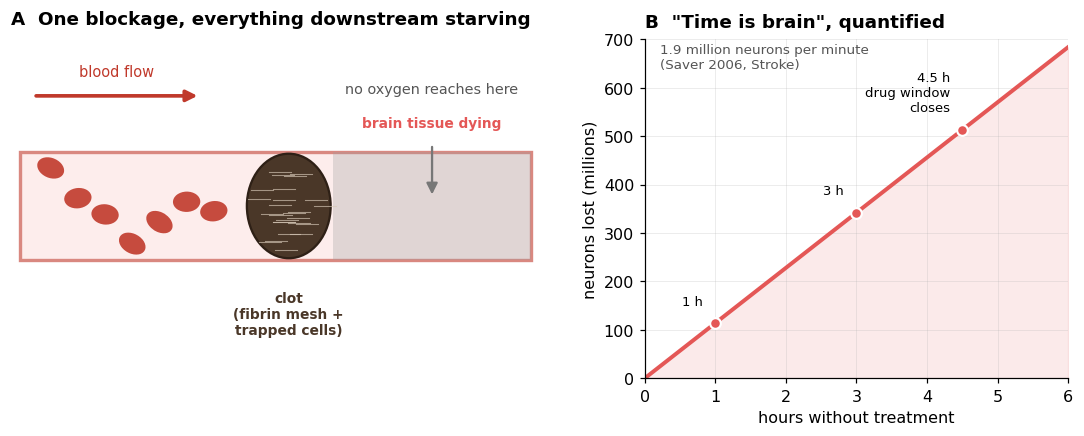

In [71]:
fig = plt.figure(figsize=(12.4, 4.0))
gs = gridspec.GridSpec(1, 2, width_ratios=[1.25, 1], wspace=0.22, figure=fig)

# ---------------- panel A: a blocked artery
ax = canvas(fig.add_subplot(gs[0]), (0, 12), (0, 6))
ax.add_patch(Rectangle((0.2, 2.1), 11.6, 1.9, facecolor="#FDEDEC",
                       edgecolor=CLR["vessel"], linewidth=2.2))
# healthy flow upstream
rng = np.random.default_rng(3)
for cx in np.linspace(0.9, 4.6, 7):
    cy = 3.05 + rng.normal(0, 0.33)
    ax.add_patch(Ellipse((cx, cy), 0.62, 0.36, angle=rng.uniform(-25, 25),
                         facecolor=CLR["rbc"], edgecolor="none", alpha=0.9))
# the clot
ax.add_patch(Ellipse((6.3, 3.05), 1.9, 1.85, facecolor=CLR["clot"],
                     edgecolor="#2E2016", linewidth=1.5))
for _ in range(26):                      # fibrin strands across the clot
    a = rng.uniform(0, 2*np.pi); r = rng.uniform(0.1, 0.85)
    ax.plot([6.3 + r*np.cos(a) - 0.25, 6.3 + r*np.cos(a) + 0.25],
            [3.05 + r*np.sin(a)*0.95]*2, color="#D7C9B8", lw=0.7, alpha=0.65)
# starved territory downstream
ax.add_patch(Rectangle((7.3, 2.1), 4.5, 1.9, facecolor=CLR["dead"],
                       alpha=0.30, edgecolor="none"))
arrow(ax, (0.5, 5.0), (4.3, 5.0), color=CLR["rbc"], lw=2.4)
ax.text(2.4, 5.35, "blood flow", ha="center", fontsize=9.6, color=CLR["rbc"])
ax.text(6.3, 1.55, "clot\n(fibrin mesh +\ntrapped cells)", ha="center",
        va="top", fontsize=9.0, color=CLR["clot"], fontweight="bold")
ax.text(9.55, 5.05, "no oxygen reaches here", ha="center", fontsize=9.4,
        color="#555")
ax.text(9.55, 4.45, "brain tissue dying", ha="center", fontsize=9.0,
        color=CLR["accent"], fontweight="bold")
arrow(ax, (9.55, 4.15), (9.55, 3.2), color="#777", lw=1.5)
ax.set_title("A  One blockage, everything downstream starving",
             loc="left", pad=10)

# ---------------- panel B: the clock
ax = fig.add_subplot(gs[1])
t = np.linspace(0, 6, 300)
neurons = 1.9e6 * 60 * t / 1e6          # millions of neurons
ax.plot(t, neurons, color=CLR["accent"], lw=2.6)
ax.fill_between(t, 0, neurons, color=CLR["accent"], alpha=0.12)
for hr, lab in [(1, "1 h"), (3, "3 h"), (4.5, "4.5 h\ndrug window\ncloses")]:
    ax.plot([hr], [1.9e6*60*hr/1e6], "o", color=CLR["accent"], ms=7,
            mec="white", mew=1.4, zorder=5)
    ax.annotate(lab, (hr, 1.9e6*60*hr/1e6), textcoords="offset points",
                xytext=(-8, 12), fontsize=8.6, ha="right")
ax.set_xlim(0, 6); ax.set_ylim(0, 700)
tidy(ax, "B  \"Time is brain\", quantified",
     "hours without treatment", "neurons lost (millions)")
ax.text(0.22, 640, "1.9 million neurons per minute\n(Saver 2006, Stroke)",
        fontsize=8.8, color="#555")

plt.tight_layout()
plt.show()

## A3. The current treatment, and the flaw in it

The clot-dissolving drug is **tPA** (tissue plasminogen activator). The two
forms used in practice are **alteplase** and **tenecteplase**.

Here is the part worth getting right, because it is the mechanism the whole
project depends on: **tPA does not dissolve the clot itself.** It is a
switch. The clot is held together by a mesh of a protein called **fibrin**,
and your blood already contains an inactive enzyme, **plasminogen**, sitting
on that mesh. tPA converts plasminogen into its active form, **plasmin**, and
plasmin is what cuts the fibrin.

The body also has brakes on this system — **PAI-1** blocks tPA, and
**antiplasmin** blocks plasmin — which is why the clot does not simply keep
dissolving forever.

**Why this is dangerous.** The drug is given into a vein, so it travels
everywhere. Only a tiny fraction ever meets the clot. The rest is still
active, and it will happily dissolve the small useful clots that are patching
up minor injuries all over your body. The feared complication is bleeding
into the brain.

So clinicians are forced into a trade: enough drug to open the artery, not so
much that the patient bleeds. That trade is why the treatment window is narrow
and why many patients are never eligible.

/var/folders/3k/2bp7npfs623cpzprlfwry4f40000gp/T/ipykernel_13881/3145162003.py:57: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


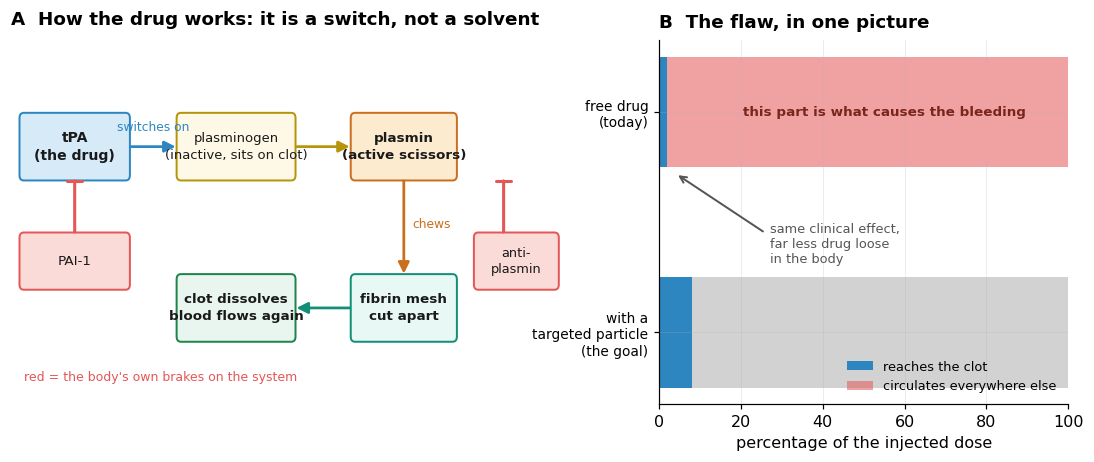

In [72]:
fig = plt.figure(figsize=(12.4, 4.3))
gs = gridspec.GridSpec(1, 2, width_ratios=[1.35, 1], wspace=0.20, figure=fig)

# ---------------- panel A: the cascade
ax = canvas(fig.add_subplot(gs[0]), (0, 13), (0, 7))
box(ax, 0.3, 4.4, 2.4, 1.1, "tPA\n(the drug)", fc="#D6EAF8", ec=CLR["drug"],
    weight="bold")
box(ax, 4.0, 4.4, 2.6, 1.1, "plasminogen\n(inactive, sits on clot)",
    fc="#FEF9E7", ec="#B7950B", fs=8.6)
box(ax, 8.1, 4.4, 2.3, 1.1, "plasmin\n(active scissors)", fc="#FDEBD0",
    ec="#CA6F1E", fs=8.8, weight="bold")
box(ax, 8.1, 1.3, 2.3, 1.1, "fibrin mesh\ncut apart", fc="#E8F8F5",
    ec="#148F77", fs=8.8, weight="bold")
box(ax, 4.0, 1.3, 2.6, 1.1, "clot dissolves\nblood flows again", fc="#E8F6EF",
    ec="#1E8449", fs=8.8, weight="bold")

arrow(ax, (2.75, 4.95), (3.95, 4.95), color=CLR["drug"])
ax.text(3.35, 5.25, "switches on", ha="center", fontsize=8.0, color=CLR["drug"])
arrow(ax, (6.65, 4.95), (8.05, 4.95), color="#B7950B")
arrow(ax, (9.25, 4.35), (9.25, 2.45), color="#CA6F1E")
ax.text(9.45, 3.4, "chews", fontsize=8.0, color="#CA6F1E")
arrow(ax, (8.05, 1.85), (6.65, 1.85), color="#148F77")

# the brakes
box(ax, 0.3, 2.3, 2.4, 0.9, "PAI-1", fc="#FADBD8", ec=CLR["accent"], fs=8.8)
box(ax, 11.0, 2.3, 1.8, 0.9, "anti-\nplasmin", fc="#FADBD8", ec=CLR["accent"],
    fs=8.4)
blunt(ax, (1.5, 3.25), (1.5, 4.35))
blunt(ax, (11.6, 3.25), (11.6, 4.35))
ax.text(0.3, 0.45, "red = the body's own brakes on the system", fontsize=8.2,
        color=CLR["accent"])
ax.set_title("A  How the drug works: it is a switch, not a solvent",
             loc="left", pad=10)

# ---------------- panel B: where the dose goes
ax = fig.add_subplot(gs[1])
frac = [2.0, 98.0]
ax.barh([1], [frac[0]], 0.5, color=CLR["drug"], label="reaches the clot")
ax.barh([1], [frac[1]], 0.5, left=[frac[0]], color=CLR["accent"], alpha=0.55,
        label="circulates everywhere else")
ax.barh([0], [100], 0.5, color=CLR["grey"], alpha=0.35)
ax.barh([0], [8], 0.5, color=CLR["drug"])
ax.set_yticks([0, 1])
ax.set_yticklabels(["with a\ntargeted particle\n(the goal)",
                    "free drug\n(today)"], fontsize=9)
ax.set_xlim(0, 100)
ax.legend(fontsize=8.4, loc="lower right")
tidy(ax, "B  The flaw, in one picture",
     "percentage of the injected dose")
ax.text(55, 1.0, "this part is what causes the bleeding", ha="center",
        va="center", fontsize=8.8, color="#7B241C", fontweight="bold")
ax.annotate("", xy=(4, 0.72), xytext=(26, 0.45),
            arrowprops=dict(arrowstyle="->", color="#555", lw=1.3))
ax.text(27, 0.40, "same clinical effect,\nfar less drug loose\nin the body",
        fontsize=8.4, color="#555", va="center")

plt.tight_layout()
plt.show()

**A note on where the field is right now**, which is worth knowing if a judge
asks whether this problem is already solved. The American Heart Association
and American Stroke Association issued a new guideline in **January 2026**,
replacing the 2018 guideline and its 2019 update. Eligible adults presenting
within 4.5 hours may now receive **either tenecteplase (0.25 mg/kg) or
alteplase (0.9 mg/kg)** — tenecteplase as a single bolus, alteplase as a bolus
followed by an hour-long infusion. Selected patients with unknown onset time,
or 4.5 to 9 hours out, may be treated using advanced imaging to find
salvageable tissue, and mechanical clot removal is now recommended in selected
patients up to **24 hours** after symptoms begin.

> Prabhakaran S, Gonzalez NR, Zachrison KS, et al. *2026 Guideline for the
> Early Management of Patients With Acute Ischemic Stroke.* Stroke, published
> online 26 January 2026. doi:10.1161/STR.0000000000000513

So the field is moving — but notice *how* it is moving: toward faster
logistics, better imaging, and physically pulling the clot out at specialised
centres. **None of that changes the drug's basic problem**, which is that it
is still delivered by flooding the whole bloodstream. Mechanical removal
requires a hospital with a neurointerventional team; the drug is what is
available nearly everywhere. Making the drug safer is still worth doing.

## A4. The idea: put the drug on a particle

If the drug could be carried on something that **collects at the clot**, the
same clinical effect would need far less drug in circulation — and less drug
in circulation means less bleeding.

This is not a new idea, and several research groups have built such particles.
The papers behind this project are the experimental versions:

| Group | What they built |
|---|---|
| **Colasuonno** | soft, flattened, disc-shaped constructs about a micrometre across |
| **Pitek** | rod-shaped particles based on tobacco mosaic virus |
| **Huang** | 165 nm vesicles |
| **de La Taille** | 315 nm polymer particles |
| **Cooley, Ye** | the underlying physics of how particles move in flowing blood |

The trouble is that each group builds a handful of particles and tests those.
Nobody can build every combination. **That gap — too many possible designs,
too few experiments — is the gap this project tries to fill.**

## A5. The one concept to get across: margination

If an audience takes away one idea, it should be this one. It is also the
idea most people get backwards.

**The instinct is that smaller is better.** Smaller particles circulate
longer, hide from the immune system, and slip into tissues. For most drug
delivery that instinct is right.

**For a clot, it is wrong, and the reason is red blood cells.**

Blood is roughly 40% red blood cells by volume. They are large (about
8 micrometres), flexible, and in flowing blood they crowd into the middle of
the vessel where flow is fastest. This leaves a thin layer right against the
wall with almost no cells in it — the **cell-free layer** — and it means the
red cells are constantly shoving anything that is *not* a red cell outwards,
toward the wall. That sideways drift is called **margination**.

Now the key consequence:

> A clot is on the **wall**. A particle too small for red blood cells to push
> on just follows the fluid down the middle of the vessel and **never gets to
> the wall at all.**

So there is a size below which a particle is essentially invisible to the
clot, no matter how clever its targeting chemistry. And there is a size above
which flow near the wall lifts it back off, and above which it starts to risk
plugging the smallest capillaries. **Between those limits there is a window,
and it is in the micrometre range.**

A good one-line way to say it: *"the red blood cells are the delivery
service, and a particle has to be big enough for them to notice."*

/var/folders/3k/2bp7npfs623cpzprlfwry4f40000gp/T/ipykernel_13881/442733964.py:69: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


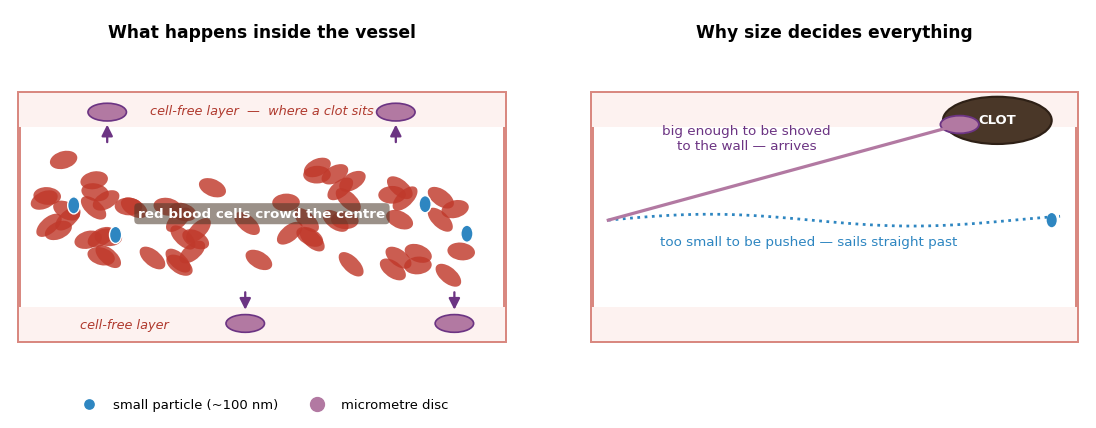

In [73]:
fig = plt.figure(figsize=(12.6, 4.6))
gs = gridspec.GridSpec(1, 2, wspace=0.14, figure=fig)
rng = np.random.default_rng(11)


def vessel(ax, title):
    canvas(ax, (0, 12), (0, 6.6))
    ax.add_patch(Rectangle((0.2, 1.0), 11.6, 4.2, facecolor="#FFFFFF",
                           edgecolor=CLR["vessel"], linewidth=2.6))
    # the cell-free layer, top and bottom
    for yy in (1.0, 4.62):
        ax.add_patch(Rectangle((0.2, yy), 11.6, 0.58, facecolor="#FDF2F0",
                               edgecolor="none"))
    ax.text(6.0, 6.15, title, ha="center", fontsize=11.2, fontweight="bold")
    return ax


# ---------------- panel A: the physical picture
ax = vessel(fig.add_subplot(gs[0]), "What happens inside the vessel")
for _ in range(58):                                  # red cells crowd the core
    cx = rng.uniform(0.6, 11.4); cy = 3.1 + rng.normal(0, 0.46)
    cy = np.clip(cy, 2.05, 4.15)
    ax.add_patch(Ellipse((cx, cy), 0.66, 0.30, angle=rng.uniform(-30, 30),
                         facecolor=CLR["rbc"], edgecolor="none", alpha=0.82))
ax.text(6.0, 3.1, "red blood cells crowd the centre", ha="center",
        fontsize=8.8, color="white", fontweight="bold",
        bbox=dict(boxstyle="round,pad=0.3", fc=CLR["clot"], ec="none",
                  alpha=0.55))
ax.text(6.0, 4.90, "cell-free layer  —  where a clot sits", ha="center",
        va="center", fontsize=8.4, color="#B03A2E", style="italic")
ax.text(2.7, 1.28, "cell-free layer", ha="center", va="center",
        fontsize=8.4, color="#B03A2E", style="italic")
# small particles stuck in midstream
for cx, cy in [(1.5, 3.30), (2.5, 2.80), (9.9, 3.32), (10.9, 2.82)]:
    ax.add_patch(Circle((cx, cy), 0.145, facecolor=CLR["drug"],
                        edgecolor="white", linewidth=0.9, zorder=6))
# big discs pushed out to both walls
for cx, cy in [(2.3, 4.88), (5.6, 1.30), (9.2, 4.88), (10.6, 1.30)]:
    ax.add_patch(Ellipse((cx, cy), 0.92, 0.30, facecolor=CLR["oblate"],
                         edgecolor="#6C3483", linewidth=1.1))
for cx, cy, dy in [(2.3, 4.32, 0.40), (9.2, 4.32, 0.40),
                   (5.6, 1.88, -0.40), (10.6, 1.88, -0.40)]:
    arrow(ax, (cx, cy), (cx, cy + dy), color="#6C3483", lw=1.5)
ax.plot([], [], "o", color=CLR["drug"], ms=6, label="small particle (~100 nm)")
ax.plot([], [], "o", color=CLR["oblate"], ms=9, label="micrometre disc")
ax.legend(fontsize=8.6, loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.06))

# ---------------- panel B: the consequence
ax = vessel(fig.add_subplot(gs[1]), "Why size decides everything")
ax.add_patch(Ellipse((9.9, 4.74), 2.6, 0.80, facecolor=CLR["clot"],
                     edgecolor="#2E2016", linewidth=1.4))
ax.text(9.9, 4.74, "CLOT", ha="center", va="center", fontsize=8.6,
        color="white", fontweight="bold")
# small particle: straight down the middle, sails past
ax.plot(np.linspace(0.6, 11.4, 60), 3.05 + 0.10*np.sin(
        np.linspace(0, 7, 60)), color=CLR["drug"], lw=1.8, ls=":")
ax.add_patch(Circle((11.2, 3.05), 0.12, facecolor=CLR["drug"], edgecolor="none"))
ax.text(5.4, 2.62, "too small to be pushed — sails straight past",
        fontsize=8.8, color=CLR["drug"], ha="center")
# disc: drifts outward and lands on the clot
xs = np.linspace(0.6, 9.0, 60)
ys = 3.05 + 1.62 * (xs - 0.6) / 8.4
ax.plot(xs, ys, color=CLR["oblate"], lw=2.1)
ax.add_patch(Ellipse((9.0, 4.67), 0.92, 0.30, facecolor=CLR["oblate"],
                     edgecolor="#6C3483", linewidth=1.2))
ax.text(3.9, 4.25, "big enough to be shoved\nto the wall — arrives",
        fontsize=8.8, color="#6C3483", ha="center")

plt.tight_layout()
plt.show()

## A6. The four knobs, and why they fight each other

A particle can be varied in four ways. The field calls them the **4S
parameters**. Every one of them helps in one place and hurts in another, which
is exactly why the answer has to be computed instead of argued.

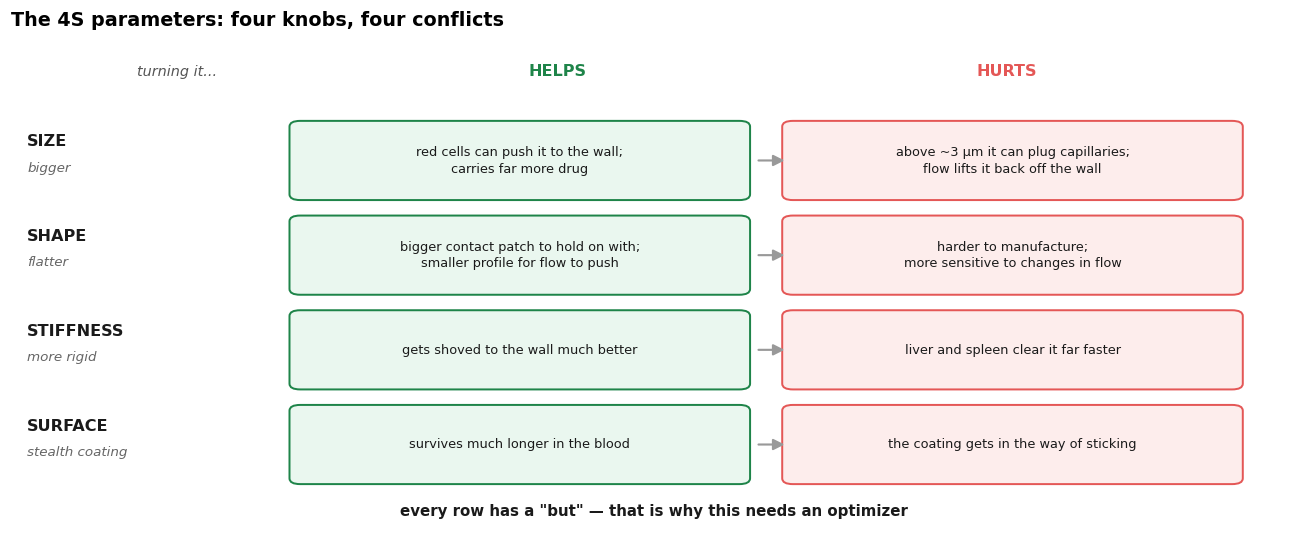

In [74]:
fig, ax = plt.subplots(figsize=(12.0, 5.0))
canvas(ax, (0, 12), (0, 8.4))

rows = [
    ("SIZE",      "bigger",   "red cells can push it to the wall;\ncarries far more drug",
                  "above ~3 µm it can plug capillaries;\nflow lifts it back off the wall"),
    ("SHAPE",     "flatter",  "bigger contact patch to hold on with;\nsmaller profile for flow to push",
                  "harder to manufacture;\nmore sensitive to changes in flow"),
    ("STIFFNESS", "more rigid", "gets shoved to the wall much better",
                  "liver and spleen clear it far faster"),
    ("SURFACE",   "stealth coating", "survives much longer in the blood",
                  "the coating gets in the way of sticking"),
]
ax.text(1.55, 7.85, "turning it...", fontsize=9.4, style="italic", ha="center",
        color="#555")
ax.text(5.1, 7.85, "HELPS", fontsize=10.5, fontweight="bold", ha="center",
        color="#1E8449")
ax.text(9.3, 7.85, "HURTS", fontsize=10.5, fontweight="bold", ha="center",
        color=CLR["accent"])

for i, (knob, dirn, good, bad) in enumerate(rows):
    y = 6.2 - i * 1.65
    ax.text(0.15, y + 0.42, knob, fontsize=10.6, fontweight="bold",
            color="#1A1A1A")
    ax.text(0.15, y - 0.02, dirn, fontsize=8.8, style="italic", color="#666")
    box(ax, 2.7, y - 0.42, 4.1, 1.18, good, fc="#EAF7EF", ec="#1E8449", fs=8.4)
    box(ax, 7.3, y - 0.42, 4.1, 1.18, bad, fc="#FDEDEC", ec=CLR["accent"],
        fs=8.4)
    arrow(ax, (6.95, y + 0.17), (7.25, y + 0.17), color="#999", lw=1.4)

ax.text(6.0, 0.18, "every row has a \"but\" — that is why this needs an optimizer",
        ha="center", fontsize=9.8, fontweight="bold", color="#1A1A1A")
ax.set_title("The 4S parameters: four knobs, four conflicts", loc="left",
             fontsize=12.5, pad=12)
plt.tight_layout()
plt.show()

The deepest conflict is **stiffness**, and it is worth being able to state it
cleanly: a rigid particle is pushed to the vessel wall much more effectively,
but the liver and spleen clear it from the bloodstream far faster. A soft
particle survives for many hours — this is thought to be part of why red blood
cells, which are extremely floppy, last about four months — but it deforms and
slips back into midstream instead of marginating.

**Rigid arrives but does not last. Soft lasts but does not arrive.** There is
no setting that gets both.

## A7. What this project actually did

Four steps. It is worth being able to walk through them in order, because the
third one is what makes the project a piece of science rather than a
simulation that agrees with itself.

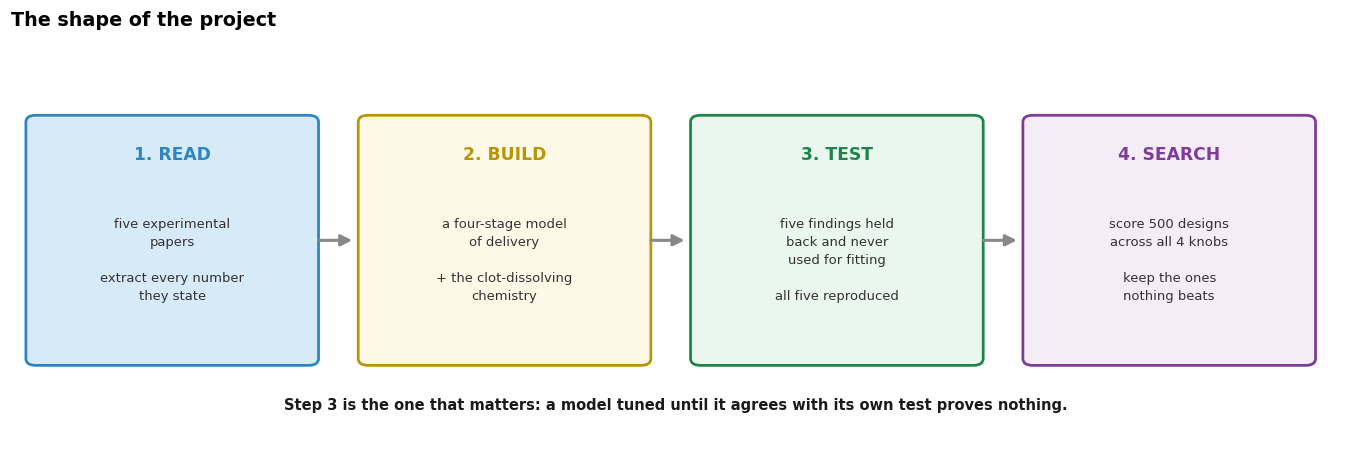

In [75]:
fig, ax = plt.subplots(figsize=(12.4, 4.4))
canvas(ax, (0, 13.4), (0, 6.2))

steps = [
    ("1. READ", "five experimental\npapers\n\nextract every number\nthey state",
     "#D6EAF8", "#2E86C1"),
    ("2. BUILD", "a four-stage model\nof delivery\n\n+ the clot-dissolving\nchemistry",
     "#FEF9E7", "#B7950B"),
    ("3. TEST", "five findings held\nback and never\nused for fitting\n\nall five reproduced",
     "#EAF7EF", "#1E8449"),
    ("4. SEARCH", "score 500 designs\nacross all 4 knobs\n\nkeep the ones\nnothing beats",
     "#F4ECF7", "#7D3C98"),
]
for i, (title_, body, fc, ec) in enumerate(steps):
    x = 0.25 + i * 3.35
    box(ax, x, 1.5, 2.75, 3.5, "", fc=fc, ec=ec, lw=1.8)
    ax.text(x + 1.375, 4.45, title_, ha="center", fontsize=11.2,
            fontweight="bold", color=ec)
    ax.text(x + 1.375, 2.95, body, ha="center", va="center", fontsize=8.6,
            color="#333", linespacing=1.5)
    if i < 3:
        arrow(ax, (x + 2.82, 3.25), (x + 3.22, 3.25), color="#888", lw=2.0)

ax.text(6.7, 0.75, "Step 3 is the one that matters: a model tuned until it "
                   "agrees with its own test proves nothing.",
        ha="center", fontsize=9.6, fontweight="bold", color="#1A1A1A")
ax.set_title("The shape of the project", loc="left", fontsize=12.5, pad=10)
plt.tight_layout()
plt.show()

**Why step 3 deserves the emphasis.** Any model with twenty constants can be
bent until it agrees with whatever you point it at. So five experimental
findings were set aside at the start and never used to choose a single
constant — things like *"a disc outperforms a sphere"* and *"take the red
cells out of the blood and the advantage disappears"*. The model had to get
those right on its own. It got all five.

That is the difference between *"my model matches the data"* and *"my model
predicted something it had never seen"*, and it is the distinction a judge
with a research background will be listening for.

## A8. Glossary — the ten words you need

| Word | Say it like this |
|---|---|
| **Ischemic stroke** | a clot blocks an artery to the brain; the tissue downstream starts dying |
| **tPA / alteplase / tenecteplase** | the clot-dissolving drug; it switches on the body's own clot-cutting enzyme |
| **Fibrin** | the protein mesh that holds a clot together |
| **Plasminogen → plasmin** | the inactive enzyme on the clot, and its active form that cuts fibrin |
| **Thrombolysis** | the dissolving of a clot |
| **Margination** | the sideways drift that pushes particles out of the bloodstream's centre toward the wall |
| **Cell-free layer** | the thin band next to the vessel wall that red cells mostly stay out of |
| **Adhesion** | whether a particle that reaches the wall actually stays stuck under flow |
| **Shear** | how fast flow changes speed across the vessel; what tries to peel a particle off |
| **Pareto front** | the set of designs where nothing else is better on *every* measure at once |

**The 4S parameters** — Size, Shape, Stiffness, Surface — are the four things
about a particle that can be designed.

## A9. Questions you will probably be asked

**"Did you make the particles?"**
No. This is a computational study. Its output is a *prediction*: a specific
design, and a quantitative claim about how much less drug it would need. The
honest framing is that this narrows down what to build first — a lab can test
a handful of designs, not thousands.

**"How do you know the model is right?"**
I do not know it is right. I know it reproduces five published findings it was
never shown, which is a stronger claim than fitting. And I tested what happens
when the guessed constants are wrong: the recommended design does not change.

**"Why is a micrometre particle better than a nanoparticle? Isn't smaller
supposed to be better?"**
This is the best question and the best answer in the project. Smaller is
better for circulating quietly, and worse for finding a clot, because
margination is driven by red blood cells and a particle too small for them to
push on never reaches the wall. The model puts the smallest particle in the
comparison — a 165 nm vesicle — dead last.

**"What would you do next?"**
Build the recommended disc and measure whether the dose reduction is real.
The model points past the papers in one specific direction — very flat discs —
and that is where it is extrapolating most, so that is where it should be
tested first.

**"What are the weaknesses?"**
Three I would name without being asked. It ignores the **protein corona** —
real particles get coated in blood proteins within seconds, which changes
their surface. It scores **one clot, one injection, sixty minutes**, which is
why it concludes a stealth coating is not worth its cost; that conclusion
should be distrusted, because stealth coatings matter for repeat dosing and
whole-body distribution, which this objective cannot see. And it treats the
clot as **uniform**, when real clots vary in density — one of the strongest
predictors of whether treatment works.

**"Couldn't you just use machine learning on the papers' data?"**
Not usefully. Across all five papers there are only a couple of hundred
usable data points, mostly read off figures. That is far too little to learn
this many interacting variables. A mechanistic model built from the physics
needs far less data, and — unlike a fitted curve — it can be checked against
findings it was never trained on.

## A10. Three misconceptions to correct up front

1. **"Nanoparticles are better because they are small."** For this job, size is
   what lets red blood cells push the particle to the wall. Below a few
   hundred nanometres the delivery mechanism simply stops working.

2. **"tPA dissolves clots."** It does not. It activates plasminogen, and
   plasmin does the cutting. This matters because it is why the dose-response
   curve flattens out: a clot carries a finite amount of plasminogen, so past
   a point more drug has nothing left to switch on.

3. **"The danger is the particle."** The danger is the *drug that misses*.
   Everything in this project is aimed at the same goal — get the same
   clinical effect with less drug loose in the bloodstream.

---

That is the whole conceptual story. **Part II** builds the model, tests it,
and runs the search.

## 0. Why this problem is worth modelling

When someone has an ischemic stroke or a heart attack, a clot is blocking a
blood vessel and the tissue downstream is dying. The standard treatment is a
drug called **tPA** (tissue plasminogen activator). tPA does not cut the clot
apart itself. It switches on an enzyme already in your blood:

> tPA finds **plasminogen** sitting on the clot → converts it into
> **plasmin** → plasmin chews through **fibrin**, the protein mesh holding
> the clot together.

It works. But it is given as an intravenous infusion, so the drug goes
everywhere in the body, not just to the clot. Two consequences:

1. **Only a tiny fraction of the dose ever touches the clot.** The clot is a
   millimetre-scale object in a circulatory system with thousands of square
   metres of vessel wall.
2. **The rest of the dose is still active.** tPA circulating in the blood can
   dissolve the normal clots that are patching up small injuries. The feared
   complication is bleeding into the brain.

That trade-off is why tPA has a narrow treatment window and why many patients
never get it. The engineering question is therefore not "can we make a better
drug" but:

> **Can we package the same drug onto a particle that concentrates it at the
> clot, so a much smaller dose does the same job?**

That is what the papers in this project are about, and it is a *design*
question: a particle has a size, a shape, a stiffness, and a surface, and
each of those changes where the particle ends up. Those four knobs are called
the **4S parameters**.

## 1. The four knobs, and why they fight each other

| Knob | What it means | The catch |
|---|---|---|
| **Size** | How big the particle is | Too small and it leaks out of vessels into tissue; too big and it plugs the smallest capillaries |
| **Shape** | Sphere, rod, or flattened disc | Non-spherical particles are pushed to the vessel wall better, but they are also easier for flow to peel off |
| **Stiffness** | Rigid plastic vs. soft gel | Rigid particles get pushed to the wall better; soft particles survive in the bloodstream far longer |
| **Surface** | Targeting molecules, stealth coating (PEG) | A stealth coating hides the particle from the immune system, but it also gets in the way of sticking to the clot |

Every row has a "but". That is the whole reason a design optimizer is needed:
there is no setting where all four knobs are simultaneously at their best, so
the answer has to come from working out where the balance lands.

The physical story has **four stages**, and a particle has to survive all of
them. The model below is built one stage at a time.

```
       Stage 1              Stage 2            Stage 3           Stage 4
    MARGINATION           ADHESION          CIRCULATION         PAYLOAD
  does it get pushed    does it stay      is it still around   how much drug
  to the vessel wall?   stuck there?      to reach the clot?   does it carry?
         |                   |                    |                 |
    red cells push      contact area vs.     liver and spleen   volume loading
    it sideways         peeling force        remove it          vs. surface
         |                   |                    |                 |
         +-------------------+--------------------+-----------------+
                                      |
                           DRUG DELIVERED AT THE CLOT
                                      |
                            fed into a lysis model
                                      |
                              HOW MUCH CLOT DISSOLVES
```

## 2. Where every number comes from

A model is only worth as much as its inputs, so every constant in it is
tagged with where it came from. Three tags are used:

- **`paper`** -- a number stated directly in one of the source papers.
- **`anchored`** -- not stated as a number, but fixed so the model reproduces
  a *qualitative* finding that a paper does state (for example, "discs
  outperform spheres").
- **`assumed`** -- a shape or scale that no paper pins down. These are the
  honest weak points, and Section 11 tests how much the conclusions move when
  they are changed.

This matters for a reason worth stating plainly: **a model that is tuned until
it agrees with its own test is not evidence of anything.** So the five
validation targets in Section 7 are kept strictly separate from the anchoring.
No constant is adjusted to make a validation target pass.

In [39]:
"""Stage 1-4: from a particle DESIGN to the drug actually delivered at the clot.

This couples the two halves of the source literature that normally sit apart:

  MARGINATION  (Ye et al. 2018 Proc R Soc A; Cooley et al. 2018 Nanoscale)
      how a particle crosses the red-cell-crowded core of the bloodstream and
      reaches the vessel wall, governed by the "4S" parameters:
      Size, Shape, Stiffness, Surface.

  WALL ADHESION (Decuzzi & Ferrari, as applied in Colasuonno et al. 2018)
      once at the wall, whether it stays: adhesive contact area versus the
      hydrodynamic force trying to dislodge it.

  CIRCULATION  (Colasuonno 2018; Bruckman 2014 via Pitek 2017)
      how long it survives to keep arriving.

EVERY constant carries a provenance tag:
  "paper"     - a number reported in the source papers
  "anchored"  - chosen so the model reproduces a reported COMPARISON
  "assumed"   - a modelling choice with no direct source

Nothing here is fitted to the four validation targets in validate.py; those are
held out deliberately, so reproducing them is a test rather than a tautology.
"""
from dataclasses import dataclass, field
import numpy as np

# ---------------------------------------------------------------- constants

In [76]:
CONST = {
    # ---- margination -------------------------------------------------------
    "marg_gain":        dict(v=6.0,    prov="anchored",
                             note="overall near-wall enrichment scale; set so a "
                                  "1 um disc is ~an order of magnitude enriched"),
    "marg_peak_nm":     dict(v=1500.0, prov="anchored",
                             note="size of peak margination; Cooley found >=500 nm "
                                  "oblate best, micron-scale still strong"),
    "marg_logwidth":    dict(v=0.62,   prov="assumed",
                             note="width of the size window, in log10 nm"),
    "hct_ref":          dict(v=0.40,   prov="paper",
                             note="Cooley tested 0, 20, 40% haematocrit"),
    "lift_coeff":       dict(v=0.16,   prov="assumed",
                             note="shear-gradient lift pushing particles off the "
                                  "wall; Ye eq 2.3 scales with a^3"),
    # ---- shape -------------------------------------------------------------
    "shape_marg": dict(v={"sphere": 1.00, "prolate": 1.45, "rod": 1.80,
                          "oblate": 2.10},
                       prov="anchored",
                       note="tumbling drives lateral drift; Cooley ranks oblate "
                            "first and rods second, spheres last"),
    # ---- stiffness ---------------------------------------------------------
    "E_half_kPa":       dict(v=120.0,  prov="assumed",
                             note="stiffness at which margination is half-maximal"),
    "soft_kPa":         dict(v=200.0,  prov="paper",
                             note="Colasuonno: soft DPNs are tens-to-hundreds kPa"),
    # ---- adhesion ----------------------------------------------------------
    "adh_gain":         dict(v=2.4,    prov="anchored"),
    "retention_floor":  dict(v=0.28,   prov="anchored",
                             note="Drug reaches a clot by bulk convection and tPA's "
                                  "own fibrin affinity even with no margination or "
                                  "firm adhesion -- free tPA works at all, so "
                                  "retention cannot fall to zero. Without this floor "
                                  "the model wrongly predicts that sub-300 nm "
                                  "particles do essentially nothing, contradicting "
                                  "Huang 2021 and de La Taille 2025."),
    "drag_ref":         dict(v=1.0,    prov="assumed"),
    "area_ref_nm2":     dict(v=1.0e5,  prov="assumed",
                             note="reference contact area, to keep the adhesion "
                                  "score dimensionless"),
    "ligand_half":      dict(v=0.008,  prov="anchored",
                             note="Marsh: raising anti-fibrin antibodies 10->40 per "
                                  "particle did NOT improve lysis. Adhesion is "
                                  "MULTIVALENT -- once enough bonds resist the drag, "
                                  "more do not help -- so the half-point sits far "
                                  "below 10 ligands and the Hill exponent is 2."),
    "ligand_hill":      dict(v=2.0,    prov="anchored"),
    # ---- circulation -------------------------------------------------------
    "t_half_soft_h":    dict(v=22.0,   prov="paper",
                             note="Colasuonno: soft discoidal PLGA/PEG, ~22 h"),
    "t_half_rigid_h":   dict(v=3.0,    prov="paper",
                             note="Colasuonno: 200 nm spheres, a few hours"),
    "peg_factor":       dict(v=1.9,    prov="anchored",
                             note="PEG 'stealth' extends circulation; Ye warns it "
                                  "also damps interaction with the target"),
    "peg_adhesion_cost": dict(v=0.80,  prov="anchored",
                              note="that same damping, applied to adhesion"),
    "clear_large_nm":   dict(v=3000.0, prov="paper",
                             note="Cooley: >3 um risks occluding capillaries"),
    # ---- safety ------------------------------------------------------------
    "extrav_mid_nm":    dict(v=420.0,  prov="anchored",
                             note="Colasuonno argues 200 nm spheres would extravasate "
                                  "at leaky vasculature while 1 um DPNs would not"),
    "extrav_steep":     dict(v=3.2,    prov="assumed"),
    "occl_mid_nm":      dict(v=2800.0, prov="paper",
                             note="Cooley: particles above ~3 um risk occluding the "
                                  "smallest capillaries. This is the opposing risk "
                                  "to extravasation, and the two together create a "
                                  "genuine size optimum rather than 'bigger is better'."),
    "occl_width_nm":    dict(v=430.0,  prov="assumed"),
    "occl_soft_relief": dict(v=0.35,   prov="paper",
                             note="Deformable particles squeeze through capillaries: "
                                  "red cells are ~8 um yet pass vessels narrower than "
                                  "themselves. Softness therefore RELIEVES occlusion "
                                  "while HURTING margination -- the central tension."),
}

C = {k: v["v"] for k, v in CONST.items()}

def constants_table():
    import pandas as pd
    return pd.DataFrame([{"constant": k, "value": (v["v"] if not isinstance(v["v"], dict)
                                                   else str(v["v"])),
                          "provenance": v["prov"], "note": v.get("note", "")}
                         for k, v in CONST.items()])

In [77]:
tbl = constants_table()
print(tbl.to_string(index=False))
print()
print(tbl["provenance"].value_counts().to_string())

         constant                                                       value provenance                                                                                                                                                                                                                                                                                                                       note
        marg_gain                                                         6.0   anchored                                                                                                                                                                                                                                  overall near-wall enrichment scale; set so a 1 um disc is ~an order of magnitude enriched
     marg_peak_nm                                                      1500.0   anchored                                                                                                        

### Reading that table

The `assumed` rows are the ones to be suspicious of. They are mostly
*widths* and *steepnesses* -- how sharply an effect turns on -- rather than
*directions*. That distinction matters: the direction of every effect in this
model comes from a paper, and only the sharpness of the transition is guessed.
A guessed steepness moves the exact size of the optimum; it does not flip
which way the optimum lies. Section 11 shows that quantitatively.

---

## 3. Stage 1 — Margination: does the particle even reach the wall?

A clot is on the **wall** of a vessel. A particle floating down the middle of
the bloodstream will never touch it. So the first question is whether the
particle gets pushed sideways, out of the fast-moving centre and into the slow
layer next to the wall. That sideways drift is called **margination**.

Here is the surprising part: **the red blood cells do it.** Blood is about 40%
red cells by volume, and they are large (about 8 micrometres), flexible, and
they crowd into the centre of the vessel where flow is fastest. That crowding
leaves a thin, nearly cell-free layer right against the wall, and it shoves
anything *not* a red cell outwards into that layer.

This is the single most important idea in the whole model, and it has a clear
consequence:

> **A particle too small to be noticed by the red cells does not get pushed
> anywhere.** It follows the fluid, stays in the middle, and never finds the
> wall.

Which is why the model has a **peak** in the micrometre range rather than
"smaller is better". Three things set it:

- **Size** -- being big enough for red cells to push on, but not so big that
  flow lifts it back off the wall (that lifting force grows roughly with the
  cube of the radius).
- **Shape** -- a flattened disc or a rod tumbles and drifts sideways far more
  than a sphere, which just rolls along.
- **Stiffness** -- a *rigid* particle gets shoved outwards; a very soft one
  deforms and slips back into the flow with the red cells.

In [42]:
@dataclass
class Particle:
    """One nanoparticle design. d_eq is the equivalent-sphere diameter in nm,
    so particles of different shape can be compared at equal VOLUME."""
    d_eq: float = 1000.0
    shape: str = "oblate"          # sphere | oblate | prolate | rod
    aspect: float = 2.5            # long axis / short axis (1.0 for a sphere)
    E_kPa: float = 200.0           # Young's modulus
    ligand: float = 0.05           # targeting ligand density, 0..1
    peg: bool = True
    surface_loaded: bool = False   # True = drug on the surface, False = in the matrix

    def volume_nm3(self):
        return np.pi / 6.0 * self.d_eq ** 3

    def dims_nm(self):
        """Physical dimensions at the same volume, given the shape/aspect ratio.
        Returns (contact_diameter, height_normal_to_wall, length_along_flow)."""
        V = self.volume_nm3()
        a = max(self.aspect, 1.0)
        if self.shape == "sphere":
            d = self.d_eq
            return d, d, d
        if self.shape == "oblate":
            # disc: diameter D, height h = D/a  ->  V = pi/4 * D^2 * h
            D = (4.0 * V * a / np.pi) ** (1.0 / 3.0)
            return D, D / a, D
        if self.shape in ("prolate", "rod"):
            # rod: diameter d, length L = a*d  ->  V = pi/4 * d^2 * L
            dd = (4.0 * V / (np.pi * a)) ** (1.0 / 3.0)
            return dd, dd, a * dd      # lies along the wall: contact width d, length L
        raise ValueError(self.shape)

    def surface_nm2(self):
        D, h, L = self.dims_nm()
        if self.shape == "sphere":
            return np.pi * D ** 2
        if self.shape == "oblate":
            return 2 * np.pi * (D / 2) ** 2 + np.pi * D * h
        return np.pi * D * L + 2 * np.pi * (D / 2) ** 2

def margination(p: Particle, hct=0.40, shear_s=800.0, c=C):
    """Near-wall enrichment factor (1.0 = no enrichment over bulk).

    Physics being encoded, all from the source reviews:
      * red cells drive the effect -- with no red cells there is no margination
        advantage at all (Cooley: in buffer everything adhered similarly)
      * there is a size window: too small and the particle is swept along inside
        the red-cell core, large is better up to the micron scale
      * non-spherical particles tumble, which drives lateral drift (Ye)
      * stiff particles marginate; soft ones stay nearer the centreline (Ye)
      * shear-gradient lift pushes particles back off the wall, and grows
        steeply with size (Ye eq 2.3, ~a^3)
    """
    d = p.d_eq
    size_term = np.exp(-((np.log10(d) - np.log10(c["marg_peak_nm"])) ** 2)
                       / (2 * c["marg_logwidth"] ** 2))

    shp = c["shape_marg"].get(p.shape, 1.0)
    # elongation helps, with diminishing returns
    aspect_term = 1.0 + 0.25 * np.log1p(max(p.aspect, 1.0) - 1.0)
    shape_term = shp * aspect_term if p.shape != "sphere" else 1.0

    stiff_term = np.sqrt(p.E_kPa / (p.E_kPa + c["E_half_kPa"]))

    # lift away from the wall: grows with size and with shear
    lift = c["lift_coeff"] * (shear_s / 800.0) * (d / c["marg_peak_nm"]) ** 3

    rbc_drive = hct / c["hct_ref"]
    return float(1.0 + c["marg_gain"] * rbc_drive * size_term * shape_term
                 * stiff_term / (1.0 + lift))

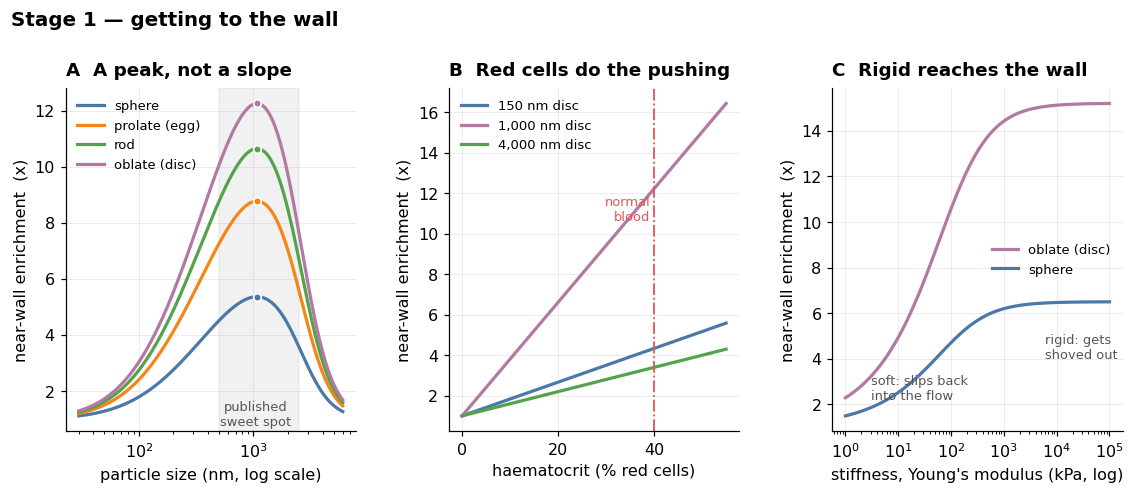

In [78]:
fig = plt.figure(figsize=(12.4, 4.4))
gs = gridspec.GridSpec(1, 3, wspace=0.32, figure=fig)
d = np.logspace(np.log10(30), np.log10(6000), 220)

# --- panel A: the size window, one line per shape
ax = fig.add_subplot(gs[0])
for sh in ["sphere", "prolate", "rod", "oblate"]:
    y = [margination(Particle(d_eq=x, shape=sh, aspect=2.5, E_kPa=200)) for x in d]
    ax.plot(d, y, color=CLR[sh], lw=2.1, label=SHAPE_LABEL[sh])
    k = int(np.argmax(y))
    ax.plot(d[k], y[k], "o", color=CLR[sh], ms=5, mec="white", mew=1.1)
ax.set_xscale("log")
ax.axvspan(500, 2500, color=CLR["grey"], alpha=0.10, zorder=0)
ax.text(1050, ax.get_ylim()[1]*0.06, "published\nsweet spot", ha="center",
        fontsize=8.5, color="#555")
ax.legend(fontsize=8.6, loc="upper left")
tidy(ax, "A  A peak, not a slope",
     "particle size (nm, log scale)", "near-wall enrichment  (x)")

# --- panel B: it is the red cells doing the work
ax = fig.add_subplot(gs[1])
hcts = np.linspace(0.0, 0.55, 60)
for size, col in [(150, CLR["sphere"]), (1000, CLR["oblate"]),
                  (4000, CLR["rod"])]:
    y = [margination(Particle(d_eq=size, shape="oblate", aspect=2.5,
                              E_kPa=200), hct=h) for h in hcts]
    ax.plot(hcts*100, y, color=col, lw=2.1, label=f"{size:,} nm disc")
ax.axvline(40, color=CLR["accent"], lw=1.2, ls="-.")
ax.text(39.2, ax.get_ylim()[1]*0.62, "normal\nblood", fontsize=8.5,
        ha="right", color=CLR["accent"])
ax.legend(fontsize=8.6, loc="upper left")
tidy(ax, "B  Red cells do the pushing",
     "haematocrit (% red cells)", "near-wall enrichment  (x)")

# --- panel C: stiffness
ax = fig.add_subplot(gs[2])
E = np.logspace(0, 5, 120)
for sh in ["oblate", "sphere"]:
    y = [margination(Particle(d_eq=1000, shape=sh, aspect=2.5, E_kPa=e)) for e in E]
    ax.plot(E, y, color=CLR[sh], lw=2.1, label=SHAPE_LABEL[sh])
ax.set_xscale("log")
ax.annotate("soft: slips back\ninto the flow", (3, 2.2), fontsize=8.5,
            color="#555")
ax.annotate("rigid: gets\nshoved out", (6e3, 4.0), fontsize=8.5, color="#555")
ax.legend(fontsize=8.6, loc="center right")
tidy(ax, "C  Rigid reaches the wall",
     "stiffness, Young's modulus (kPa, log)", "near-wall enrichment  (x)")

fig.suptitle("Stage 1 — getting to the wall", x=0.085, ha="left",
             fontsize=13, fontweight="bold")
plt.subplots_adjust(top=0.82)
plt.show()

**What panel A is saying.** Below roughly 300 nm the curve collapses. That is
the quiet problem with the "nanoparticle" instinct: a 100 nm particle is
superb at hiding from the immune system and circulating for a long time, and
almost useless at finding a vessel wall. Above roughly 3 micrometres the
curve falls again, because flow near the wall exerts a lifting force that
scales steeply with size and peels the particle back off.

**Panel C is the first real conflict.** Rigid wins here. Hold on to that,
because in Stage 3 it reverses completely.

---

## 4. Stage 2 — Adhesion: having arrived, does it stay?

Reaching the wall is not the same as sticking to it. At the wall the particle
is in a shear flow trying to roll it away, and it is held on by targeting
molecules (**ligands**) gripping the clot. Whether it stays is a tug of war,
and the standard way to think about it is the **Decuzzi balance**:

> **sticking** grows with the **contact patch** -- how much particle surface
> is flattened against the wall, which is where the bonds are.
>
> **peeling** grows with the **cross-section** the particle presents to the
> flow -- how much of it sticks up into the stream to be pushed on.

This immediately explains the shape result. Flatten a sphere into a disc at
constant volume and the contact patch grows while the profile facing the flow
shrinks. Both terms move the right way at once. A disc is simply a better
shape for holding on, which is why flattened particles keep winning in
experiments.

One more feature matters, and it is easy to get wrong: **adding more targeting
molecules stops helping.** Once the contact patch has enough bonds to resist
the flow, the next ligand does nothing -- the particle cannot be more stuck
than stuck. So adhesion *saturates* in ligand density, and the model uses a
saturating (Hill) form rather than a straight line.

There is also a floor. Free tPA, with no particle and no targeting at all,
still dissolves clots -- that is the current standard of care. So retention
can never be zero, and the model carries a `retention_floor`.

In [44]:
def adhesion(p: Particle, shear_s=800.0, c=C):
    """Probability a particle that has reached the wall actually stays there.

    Decuzzi's balance, as quoted in Colasuonno: adhesion strength scales with
    the CONTACT AREA the particle presents to the wall, while the dislodging
    hydrodynamic force scales with the CROSS-SECTION it presents to the flow.
    A flat disc maximises the first and minimises the second; a sphere is the
    worst case on both counts. Ligand density saturates early (Marsh).
    """
    D, h, L = p.dims_nm()
    if p.shape == "sphere":
        contact = np.pi * (0.12 * D) ** 2       # small Hertzian patch
        crosssec = np.pi * (D / 2) ** 2         # full circle into the flow
    elif p.shape == "oblate":
        contact = np.pi * (D / 2) ** 2          # lies flat: the whole face
        crosssec = D * h                        # thin edge into the flow
    else:                                        # rod / prolate lying along flow
        contact = 0.35 * D * L
        crosssec = D * h

    # softer particles deform onto the wall -> more real contact
    contact *= 1.0 + 0.6 * (c["E_half_kPa"] / (p.E_kPa + c["E_half_kPa"]))

    geom  = contact / crosssec                               # shape advantage
    bonds = (contact / c["area_ref_nm2"]) ** 0.30            # sub-linear in area
    n = c["ligand_hill"]
    lig = p.ligand ** n / (p.ligand ** n + c["ligand_half"] ** n)
    if p.peg:
        lig *= c["peg_adhesion_cost"]                        # stealth damps binding
    drag = (shear_s / 800.0) * (crosssec / c["area_ref_nm2"]) ** 0.5

    score = c["adh_gain"] * lig * np.sqrt(geom) * bonds / (c["drag_ref"] + drag)
    firm = 1.0 - np.exp(-score)
    # a floor for bulk delivery that does not depend on margination at all
    f = c["retention_floor"]
    return float(f + (1.0 - f) * firm)

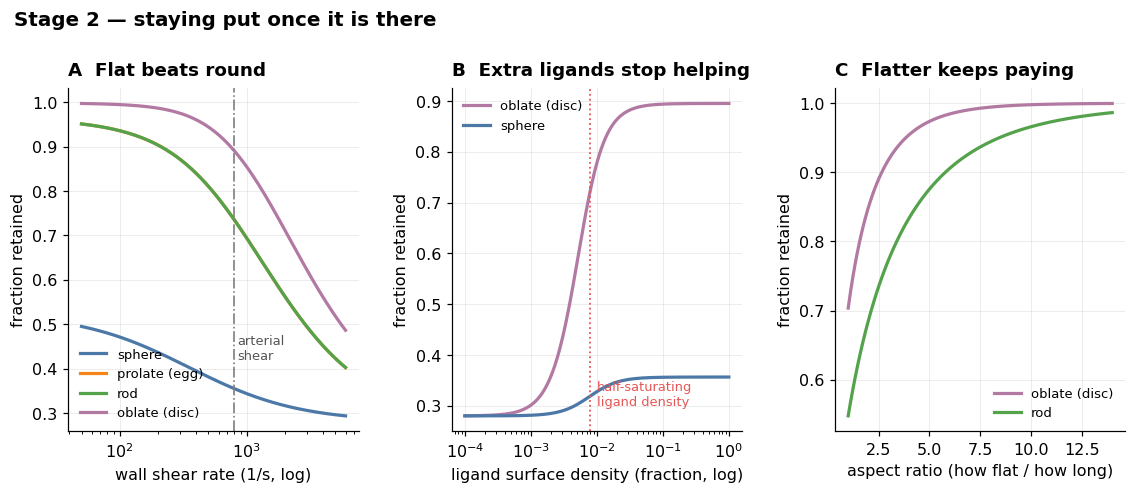

In [45]:
fig = plt.figure(figsize=(12.4, 4.4))
gs = gridspec.GridSpec(1, 3, wspace=0.32, figure=fig)

# --- A: shape at equal volume
ax = fig.add_subplot(gs[0])
shear = np.logspace(np.log10(50), np.log10(6000), 160)
for sh in ["sphere", "prolate", "rod", "oblate"]:
    y = [adhesion(Particle(d_eq=1000, shape=sh, aspect=2.5, E_kPa=200,
                           ligand=0.05), shear_s=s) for s in shear]
    ax.plot(shear, y, color=CLR[sh], lw=2.1, label=SHAPE_LABEL[sh])
ax.set_xscale("log")
ax.axvline(800, color=CLR["grey"], lw=1.1, ls="-.")
ax.text(840, 0.42, "arterial\nshear", fontsize=8.5, color="#555")
ax.legend(fontsize=8.6, loc="lower left")
tidy(ax, "A  Flat beats round",
     "wall shear rate (1/s, log)", "fraction retained")

# --- B: ligand saturation
ax = fig.add_subplot(gs[1])
lig = np.logspace(-4, 0, 160)
for sh in ["oblate", "sphere"]:
    y = [adhesion(Particle(d_eq=1000, shape=sh, aspect=2.5, E_kPa=200,
                           ligand=l)) for l in lig]
    ax.plot(lig, y, color=CLR[sh], lw=2.1, label=SHAPE_LABEL[sh])
ax.set_xscale("log")
ax.axvline(C["ligand_half"], color=CLR["accent"], lw=1.2, ls=":")
ax.text(C["ligand_half"]*1.25, 0.30, "half-saturating\nligand density",
        fontsize=8.5, color=CLR["accent"])
ax.legend(fontsize=8.6, loc="upper left")
tidy(ax, "B  Extra ligands stop helping",
     "ligand surface density (fraction, log)", "fraction retained")

# --- C: the Decuzzi balance made visible
ax = fig.add_subplot(gs[2])
asp = np.linspace(1.0, 14, 120)
for sh in ["oblate", "rod"]:
    y = [adhesion(Particle(d_eq=1000, shape=sh, aspect=a, E_kPa=200,
                           ligand=0.05)) for a in asp]
    ax.plot(asp, y, color=CLR[sh], lw=2.1, label=SHAPE_LABEL[sh])
ax.legend(fontsize=8.6, loc="lower right")
tidy(ax, "C  Flatter keeps paying",
     "aspect ratio (how flat / how long)", "fraction retained")

fig.suptitle("Stage 2 — staying put once it is there", x=0.085, ha="left",
             fontsize=13, fontweight="bold")
plt.subplots_adjust(top=0.82)
plt.show()

---

## 5. Stage 3 — Circulation: is the particle still in the blood at all?

The body removes foreign particles. The liver and spleen host the
**mononuclear phagocyte system**, a population of cells whose job is to find
and eat things that do not belong. How long a particle survives depends on two
things, and both of them cut against Stages 1 and 2:

- **Soft particles survive far longer than rigid ones.** A rigid particle is
  recognised and taken up readily. A soft, deformable particle squeezes
  through, deforms rather than being grabbed, and persists for many hours.
  This is thought to be part of why red blood cells, which are extremely
  floppy, last about four months.
- **A PEG coating ("stealth" coating) extends survival further**, by keeping
  the blood proteins that flag a particle for removal from sticking to it.

Now put that next to what we just found:

| | Stage 1 margination | Stage 2 adhesion | Stage 3 survival |
|---|---|---|---|
| **rigid** | **better** | — | worse |
| **soft** | worse | — | **better** |
| **PEG coating** | — | worse (gets in the way) | **better** |

**Every column disagrees with the next.** This is the central tension of the
whole field, and it is why the answer has to be computed rather than reasoned
out in words.

In [79]:
def circulation_half_life_h(p: Particle, c=C):
    """Hours. Soft + PEGylated circulates longest (Colasuonno: ~22 h for soft
    discoidal PLGA/PEG vs a few hours for 200 nm spheres). Note this runs
    OPPOSITE to margination, which prefers stiff -- that tension is the whole
    reason the optimum is not obvious."""
    soft_frac = c["E_half_kPa"] / (p.E_kPa + c["E_half_kPa"])     # 1 = very soft
    base = c["t_half_rigid_h"] + (c["t_half_soft_h"] - c["t_half_rigid_h"]) * soft_frac
    if p.peg:
        base *= c["peg_factor"]
    # very large particles are filtered out quickly
    if p.d_eq > c["clear_large_nm"]:
        base *= np.exp(-(p.d_eq - c["clear_large_nm"]) / 1500.0)
    return float(base)

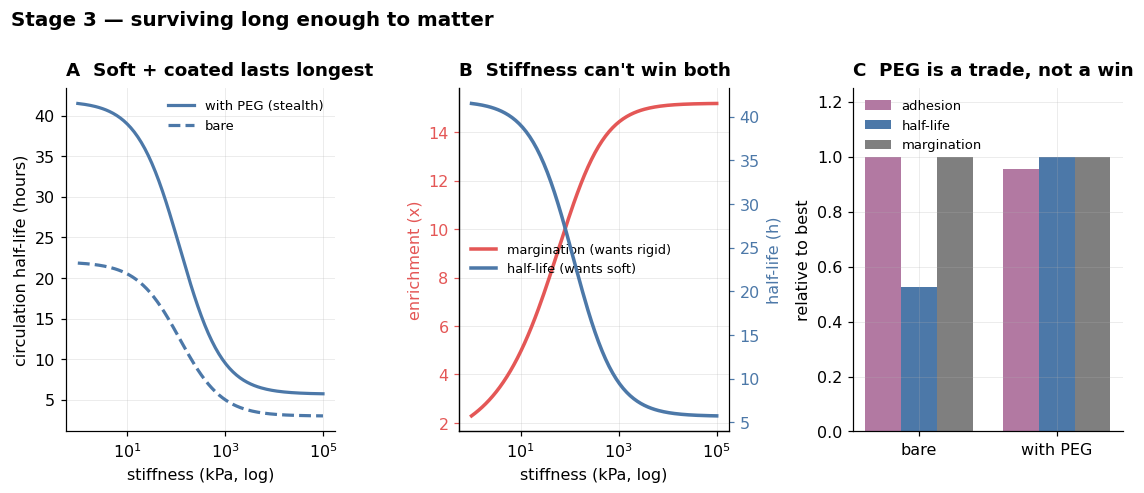

In [80]:
fig = plt.figure(figsize=(12.4, 4.4))
gs = gridspec.GridSpec(1, 3, wspace=0.46, figure=fig)
E = np.logspace(0, 5, 140)

# --- A: half-life vs stiffness
ax = fig.add_subplot(gs[0])
for peg, ls, lab in [(True, "-", "with PEG (stealth)"), (False, "--", "bare")]:
    y = [circulation_half_life_h(Particle(d_eq=1000, shape="oblate", aspect=2.5,
                                          E_kPa=e, peg=peg)) for e in E]
    ax.plot(E, y, ls, color=CLR["soft"], lw=2.1, label=lab)
ax.set_xscale("log")
ax.legend(fontsize=8.6)
tidy(ax, "A  Soft + coated lasts longest",
     "stiffness (kPa, log)", "circulation half-life (hours)")

# --- B: the tension, on twin axes
ax = fig.add_subplot(gs[1])
m = [margination(Particle(d_eq=1000, shape="oblate", aspect=2.5, E_kPa=e))
     for e in E]
t = [circulation_half_life_h(Particle(d_eq=1000, shape="oblate", aspect=2.5,
                                      E_kPa=e, peg=True)) for e in E]
ax.plot(E, m, color=CLR["rigid"], lw=2.3, label="margination (wants rigid)")
ax.set_xscale("log")
ax.set_ylabel("enrichment (x)", color=CLR["rigid"])
ax.tick_params(axis="y", colors=CLR["rigid"])
ax2 = ax.twinx()
ax2.plot(E, t, color=CLR["soft"], lw=2.3, label="half-life (wants soft)")
ax2.set_ylabel("half-life (h)", color=CLR["soft"])
ax2.tick_params(axis="y", colors=CLR["soft"])
ax2.spines["right"].set_visible(True)
ax2.grid(False)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1+h2, l1+l2, fontsize=8.4, loc="center left")
tidy(ax, "B  Stiffness can't win both", "stiffness (kPa, log)")

# --- C: what PEG costs
ax = fig.add_subplot(gs[2])
labels, marg, adh, half = [], [], [], []
for peg in (False, True):
    p = Particle(d_eq=1000, shape="oblate", aspect=2.5, E_kPa=200,
                 ligand=0.05, peg=peg)
    labels.append("with PEG" if peg else "bare")
    marg.append(margination(p)); adh.append(adhesion(p))
    half.append(circulation_half_life_h(p))
x = np.arange(2); w = 0.26
ax.bar(x-w, np.array(adh)/max(adh), w, color=CLR["oblate"], label="adhesion")
ax.bar(x,   np.array(half)/max(half), w, color=CLR["soft"], label="half-life")
ax.bar(x+w, np.array(marg)/max(marg), w, color=CLR["grey"], label="margination")
ax.set_xticks(x); ax.set_xticklabels(labels)
ax.set_ylim(0, 1.25); ax.legend(fontsize=8.6, ncol=1, loc="upper left")
tidy(ax, "C  PEG is a trade, not a win", None, "relative to best")

fig.suptitle("Stage 3 — surviving long enough to matter", x=0.085, ha="left",
             fontsize=13, fontweight="bold")
plt.subplots_adjust(top=0.82)
plt.show()

---

## 6. Stage 4 — Payload, and the two ways to be dangerous

**Payload.** How much drug a particle carries depends on *where* the drug is.
Fill the particle's interior and capacity grows with **volume**, so with the
cube of size. Attach the drug to the outside instead and capacity grows with
**surface area**, so with the square. That one exponent has a large
consequence: doubling the size of a volume-loaded particle carries eight times
the drug, so bigger particles need far fewer of them for the same dose.

**The two risks.** Dose is not free, and the danger runs in two opposite
directions at once:

- **Too small → it escapes the bloodstream.** Below a few hundred nanometres a
  particle can slip between the cells lining the vessels and into tissue. That
  is drug delivered where no clot is -- including, in the worst case, into the
  brain.
- **Too big → it blocks things.** The smallest capillaries are only a few
  micrometres across. A particle approaching that size risks plugging them,
  which causes exactly the kind of blockage the treatment is meant to relieve.

These two together are what make the size question have a real answer. One
risk falls with size, the other rises, so their sum has a **minimum** -- and
the location of that minimum is a prediction, not an input.

Softness helps here too, and for a nice reason: red blood cells are about
8 micrometres and routinely pass through capillaries narrower than themselves,
because they fold. A deformable particle behaves as though it were smaller
than it measures.

In [81]:
def payload_per_particle(p: Particle, loading_density=1.0):
    """Drug molecules per particle, in arbitrary units proportional to either
    the matrix volume or the surface area, depending on how it is loaded.
    Colasuonno's DPNs carry tPA through the porous matrix (volume); Marsh's
    perfluorocarbon and Pitek's virus carry it on the surface (area)."""
    if p.surface_loaded:
        return loading_density * p.surface_nm2() / 1e4
    return loading_density * p.volume_nm3() / 1e7

def delivered_dose(p: Particle, dose_particles=1.0, hct=0.40, shear_s=800.0,
                   window_min=60.0, loading_density=1.0, c=C):
    """Relative amount of drug delivered to the clot within the treatment window.

    arrival rate  ~  (near-wall enrichment) x (adhesion probability)
                     x (how many particles are still in circulation)
    integrated over the window, times the payload each particle carries.
    """
    M = margination(p, hct=hct, shear_s=shear_s, c=c)
    A = adhesion(p, shear_s=shear_s, c=c)
    t_half_min = circulation_half_life_h(p, c=c) * 60.0
    k = np.log(2.0) / t_half_min
    # integral of exp(-k t) over the window
    avail = (1.0 - np.exp(-k * window_min)) / k
    pay = payload_per_particle(p, loading_density)
    return {
        "margination": M, "adhesion": A,
        "t_half_h": t_half_min / 60.0,
        "payload_per_particle": pay,
        "circulating_integral_min": avail,
        "delivered": float(dose_particles * M * A * avail * pay),
    }

def offtarget_risk(p: Particle, dose_particles=1.0, c=C):
    """Proxy for bleeding risk: drug that is NOT at the clot and can leave the
    bloodstream. Colasuonno's argument is that ~200 nm spheres extravasate at
    leaky vasculature and deposit tPA in brain tissue, while ~1 um discoidal
    constructs are too large to do so. Smaller => riskier."""
    extrav = 1.0 / (1.0 + (p.d_eq / c["extrav_mid_nm"]) ** c["extrav_steep"])
    pay = payload_per_particle(p)
    return float(dose_particles * pay * extrav)

def occlusion_risk(p: "Particle", c=C):
    """Risk of plugging the smallest capillaries. Rises steeply with size, but
    deformable particles behave smaller than they measure."""
    soft_frac = c["E_half_kPa"] / (p.E_kPa + c["E_half_kPa"])     # 1 = very soft
    eff_d = p.d_eq * (1.0 - c["occl_soft_relief"] * soft_frac)
    z = (eff_d - c["occl_mid_nm"]) / c["occl_width_nm"]
    return float(1.0 / (1.0 + np.exp(-z)))

def total_risk(p: "Particle", dose_particles=1.0, w_extrav=1.0, w_occl=1.0, c=C):
    """The two harms pull in opposite directions on size:
       small -> extravasates into tissue (bleeding, incl. intracranial)
       large -> occludes capillaries
    Their sum is what makes the size optimum non-trivial."""
    ex = offtarget_risk(p, dose_particles=dose_particles, c=c)
    oc = occlusion_risk(p, c=c)
    return {"extravasation": ex, "occlusion": oc,
            "total": float(w_extrav * ex + w_occl * oc)}

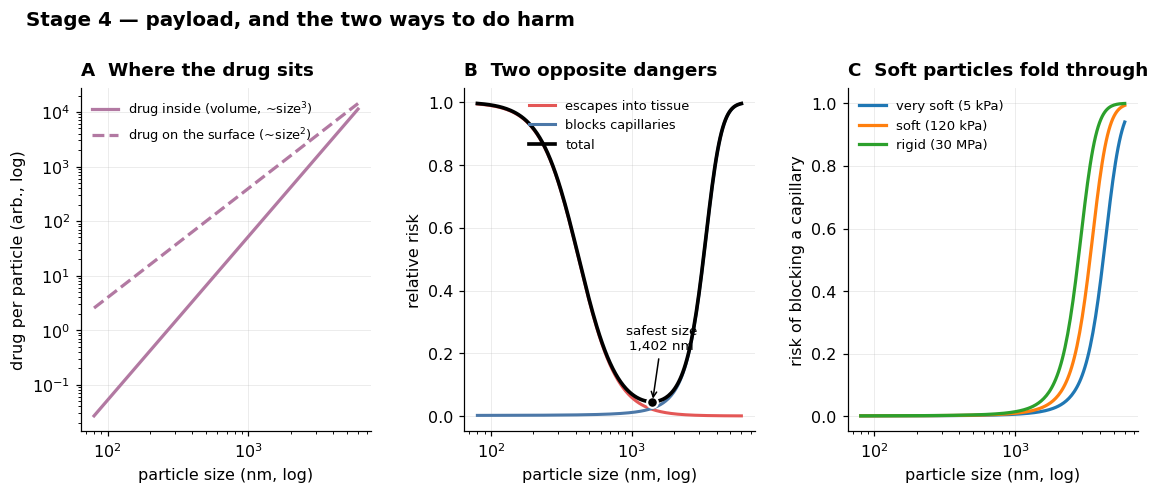

In [82]:
fig = plt.figure(figsize=(12.4, 4.4))
gs = gridspec.GridSpec(1, 3, wspace=0.32, figure=fig)
d = np.logspace(np.log10(80), np.log10(6000), 200)

# --- A: payload scaling
ax = fig.add_subplot(gs[0])
for surf, ls, lab in [(False, "-", "drug inside (volume, ~size$^3$)"),
                      (True, "--", "drug on the surface (~size$^2$)")]:
    y = [payload_per_particle(Particle(d_eq=x, shape="oblate", aspect=2.5,
                                       surface_loaded=surf)) for x in d]
    ax.plot(d, y, ls, color=CLR["oblate"], lw=2.1, label=lab)
ax.set_xscale("log"); ax.set_yscale("log")
ax.legend(fontsize=8.4, loc="upper left")
tidy(ax, "A  Where the drug sits",
     "particle size (nm, log)", "drug per particle (arb., log)")

# --- B: the two risks and their sum
ax = fig.add_subplot(gs[1])
# risk must be compared at equal DRUG DOSE, not equal particle count: a bigger
# particle carries more drug, so holding the count fixed would smuggle the
# payload scaling of panel A into the risk curve and invert it.
_ps = [Particle(d_eq=x, shape="oblate", aspect=2.5, E_kPa=200) for x in d]
ex = [offtarget_risk(p, dose_particles=1.0 / payload_per_particle(p))
      for p in _ps]
oc = [occlusion_risk(p) for p in _ps]
tot = np.array(ex) + np.array(oc)
ax.plot(d, ex, color=CLR["accent"], lw=2.0, label="escapes into tissue")
ax.plot(d, oc, color=CLR["soft"], lw=2.0, label="blocks capillaries")
ax.plot(d, tot, color="black", lw=2.4, label="total")
k = int(np.argmin(tot))
ax.plot(d[k], tot[k], "o", color="black", ms=7, mec="white", mew=1.4)
ax.annotate(f"safest size\n{d[k]:,.0f} nm", (d[k], tot[k]),
            textcoords="offset points", xytext=(6, 34), fontsize=8.8,
            ha="center", arrowprops=dict(arrowstyle="->", lw=1.0))
ax.set_xscale("log"); ax.legend(fontsize=8.4, loc="upper center")
tidy(ax, "B  Two opposite dangers",
     "particle size (nm, log)", "relative risk")

# --- C: softness buys room at the top
ax = fig.add_subplot(gs[2])
for e, lab in [(5, "very soft (5 kPa)"), (120, "soft (120 kPa)"),
               (30000, "rigid (30 MPa)")]:
    y = [occlusion_risk(Particle(d_eq=x, shape="oblate", aspect=2.5, E_kPa=e))
         for x in d]
    ax.plot(d, y, lw=2.1, label=lab)
ax.set_xscale("log"); ax.legend(fontsize=8.6, loc="upper left")
tidy(ax, "C  Soft particles fold through",
     "particle size (nm, log)", "risk of blocking a capillary")

fig.suptitle("Stage 4 — payload, and the two ways to do harm", x=0.085,
             ha="left", fontsize=13, fontweight="bold")
plt.subplots_adjust(top=0.82)
plt.show()

Panel B is the most important figure so far, and it is worth being precise
about why. Nothing in the model was told where the safe size is. The
extravasation curve comes from one paper's observation, the occlusion curve
from another's, and the minimum of their sum simply falls where it falls --
in the micrometre range, which is where the experimental papers independently
landed. **Two unrelated constraints agreeing on an answer is the kind of
result worth trusting a little.**

---

## 7. Validation — the part that decides whether any of this is worth reading

A model with twenty constants in it can be made to agree with almost
anything. So the question is not "does the model fit?" but:

> **Does the model get things right that it was never shown?**

Five findings were taken from the papers and held out. None of them was used
to set a single constant. Each one is a *direction* rather than a number,
which is deliberate -- directions are what a mechanistic model should be able
to predict, and they cannot be fitted accidentally.

| # | Held-out finding | Source of the claim |
|---|---|---|
| **V1** | A soft, flattened micrometre particle delivers far more drug than a 200 nm rigid sphere | Colasuonno — discoidal polymeric nanoconstructs |
| **V2** | Take the red cells out and the size/shape advantage disappears | Cooley — margination is red-cell-driven |
| **V3** | A rod beats a sphere of the same volume at the wall under flow | Pitek — tobacco mosaic virus rods |
| **V4** | Adhesion saturates as targeting ligands increase, but delivery keeps scaling with payload | Marsh — enzymes per particle |
| **V5** | The useful size window peaks around half a micrometre to a few micrometres | multiple |

**V4 deserves a note**, because it is the one that is hard to fake. It
requires the model to get two things right *at the same time* and in opposite
directions: adhesion must flatten out as ligands increase, while delivered
dose must keep climbing with payload. A model that got adhesion wrong by
making it linear in ligand density would pass many other tests and fail this
one.

In [83]:
"""Hold-out validation: does the delivery model reproduce findings from the
source papers that it was NOT fitted to?

If it cannot, the model has no licence to extrapolate anywhere.

  V1  Colasuonno 2018 (ACS Nano)
      Soft discoidal ~1000x400 nm polymeric nanoconstructs beat 200 nm rigid
      spheres IN VIVO -- even though the spheres dissolved clots FASTER in a
      dish. Reported cause: circulation (22 h vs hours) and wall deposition.

  V2  Cooley 2018 (Nanoscale)
      With red cells present, nanoscale spheres lose wall adhesion badly, while
      oblate (discoidal) particles >=500 nm keep adhering. Without red cells the
      difference largely disappears.

  V3  Pitek 2017 (Mol Pharm)
      Elongated tobacco mosaic virus rods (300 x 18 nm) outperform the free drug
      UNDER FLOW, attributed to tumbling and margination -- an advantage that
      does not exist in a static assay.

  V4  Marsh 2011 (Nanomedicine)
      Raising anti-fibrin antibodies from 10 to 40 per particle did NOT improve
      clot dissolution, while raising the enzyme payload from 100 to 400 DID.
      So adhesion saturates in ligand density but delivery scales with payload.
"""
import numpy as np
import pandas as pd

In [84]:
RESULTS = []

def check(name, passed, detail):
    RESULTS.append({"test": name, "passed": bool(passed), "detail": detail})
    print(f"  {'PASS' if passed else 'FAIL'}  {name}")
    print(f"        {detail}")
    return passed

def v1_discoid_vs_sphere():
    """Colasuonno: soft 1 um disc should beat the 200 nm rigid sphere on
    delivered dose, despite the sphere being the 'faster' agent in vitro."""
    dpn = Particle(d_eq=1000, shape="oblate", aspect=2.5, E_kPa=200,
                   ligand=0.05, peg=True, surface_loaded=False)
    spn = Particle(d_eq=200, shape="sphere", aspect=1.0, E_kPa=2_000,
                   ligand=0.05, peg=True, surface_loaded=True)
    a, b = delivered_dose(dpn), delivered_dose(spn)
    ratio = a["delivered"] / b["delivered"]
    return check(
        "V1 soft disc (1 um) > rigid sphere (200 nm) on delivered dose",
        3.0 < ratio < 2000.0,
        f"delivered ratio = {ratio:,.1f}x  |  disc: M={a['margination']:.2f} "
        f"A={a['adhesion']:.3f} t1/2={a['t_half_h']:.1f}h  |  sphere: "
        f"M={b['margination']:.2f} A={b['adhesion']:.3f} t1/2={b['t_half_h']:.1f}h")

def v2_rbc_dependence():
    """Cooley: the shape/size advantage is CREATED by red cells. With hct=0 it
    should nearly vanish; with hct=0.40 it should be large."""
    small_sphere = Particle(d_eq=100, shape="sphere", aspect=1.0, E_kPa=2_000)
    big_oblate = Particle(d_eq=1000, shape="oblate", aspect=3.0, E_kPa=2_000)
    r_with = margination(big_oblate, hct=0.40) / margination(small_sphere, hct=0.40)
    r_without = margination(big_oblate, hct=0.0) / margination(small_sphere, hct=0.0)
    ok = (r_with > 4.0) and (abs(r_without - 1.0) < 0.05)
    return check(
        "V2 red cells create the shape/size advantage",
        ok,
        f"oblate/sphere margination = {r_with:.2f}x at 40% haematocrit, "
        f"{r_without:.2f}x with no red cells")

def v3_rod_under_flow():
    """Pitek: an elongated rod should marginate much better than a sphere of the
    SAME VOLUME. (The static-assay disadvantage is a diffusion effect, which
    this delivery model deliberately does not include.)"""
    vol_d = 90.0                     # ~ equivalent diameter of a 300x18 nm rod
    rod = Particle(d_eq=vol_d, shape="rod", aspect=16.7, E_kPa=1_000,
                   ligand=0.05, peg=False, surface_loaded=True)
    sph = Particle(d_eq=vol_d, shape="sphere", aspect=1.0, E_kPa=1_000,
                   ligand=0.05, peg=False, surface_loaded=True)
    mr, ms = margination(rod), margination(sph)
    ar, asp = adhesion(rod), adhesion(sph)
    wall_r, wall_s = mr * ar, ms * asp
    return check(
        "V3 elongated rod > equal-volume sphere at the wall",
        wall_r / wall_s > 2.0,
        f"wall delivery ratio = {wall_r/wall_s:.2f}x  "
        f"(margination {mr:.2f} vs {ms:.2f}; adhesion {ar:.3f} vs {asp:.3f})")

def v4_ligand_saturates_payload_does_not():
    """Marsh: 10->40 antibodies gives no real gain; 100->400 payload does."""
    # Marsh's particles held ~400-1200 ligand slots, so 10 and 40 antibodies
    # correspond to fractional densities of roughly 0.025 and 0.10.
    base = dict(d_eq=300, shape="sphere", aspect=1.0, E_kPa=2_000, peg=False,
                surface_loaded=True)
    lig_lo = adhesion(Particle(ligand=0.025, **base))
    lig_hi = adhesion(Particle(ligand=0.100, **base))
    lig_gain = lig_hi / lig_lo

    p = Particle(ligand=0.05, **base)
    d_lo = delivered_dose(p, loading_density=1.0)["delivered"]
    d_hi = delivered_dose(p, loading_density=4.0)["delivered"]
    pay_gain = d_hi / d_lo

    ok = (lig_gain < 1.6) and (pay_gain > 3.5)
    return check(
        "V4 adhesion saturates in ligand density, delivery scales with payload",
        ok,
        f"4x ligand (10->40 per particle) -> {lig_gain:.2f}x adhesion   |   "
        f"4x payload -> {pay_gain:.2f}x delivered")

def v5_size_window():
    """Sanity, not from one paper: margination should peak in the sub-micron to
    micron range and fall off at both ends (Ye's size argument + Cooley's data
    + the >3 um occlusion limit)."""
    ds = np.array([50, 100, 200, 500, 1000, 2000, 3000, 5000], float)
    M = [margination(Particle(d_eq=d, shape="oblate", aspect=2.5, E_kPa=500))
         for d in ds]
    peak = ds[int(np.argmax(M))]
    ok = 500 <= peak <= 2500 and M[0] < 0.4 * max(M) and M[-1] < 0.9 * max(M)
    return check(
        "V5 margination peaks in the 0.5-2.5 um window",
        ok,
        "  ".join(f"{int(d)}nm:{m:.2f}" for d, m in zip(ds, M)))

def run_all():
    print("=" * 74)
    print(" HOLD-OUT VALIDATION against published findings")
    print("=" * 74)
    v1_discoid_vs_sphere(); v2_rbc_dependence(); v3_rod_under_flow()
    v4_ligand_saturates_payload_does_not(); v5_size_window()
    df = pd.DataFrame(RESULTS)
    n = int(df.passed.sum())
    print("=" * 74)
    print(f" {n}/{len(df)} validation targets reproduced")
    print("=" * 74)
    return df

In [85]:
RESULTS.clear()
run_all()

 HOLD-OUT VALIDATION against published findings
  PASS  V1 soft disc (1 um) > rigid sphere (200 nm) on delivered dose
        delivered ratio = 43.3x  |  disc: M=12.23 A=0.890 t1/2=19.2h  |  sphere: M=3.15 A=0.341 t1/2=7.7h
  PASS  V2 red cells create the shape/size advantage
        oblate/sphere margination = 7.79x at 40% haematocrit, 1.00x with no red cells
  PASS  V3 elongated rod > equal-volume sphere at the wall
        wall delivery ratio = 5.24x  (margination 3.49 vs 1.81; adhesion 0.926 vs 0.340)
  PASS  V4 adhesion saturates in ligand density, delivery scales with payload
        4x ligand (10->40 per particle) -> 1.02x adhesion   |   4x payload -> 4.00x delivered
  PASS  V5 margination peaks in the 0.5-2.5 um window
        50nm:1.81  100nm:3.30  200nm:6.13  500nm:11.28  1000nm:13.75  2000nm:10.88  3000nm:6.42  5000nm:2.41
 5/5 validation targets reproduced


,test,passed,detail
0,V1 soft disc (1 um) > rigid sphere (200 nm) on...,True,delivered ratio = 43.3x | disc: M=12.23 A=0....
1,V2 red cells create the shape/size advantage,True,oblate/sphere margination = 7.79x at 40% haema...
2,V3 elongated rod > equal-volume sphere at the ...,True,wall delivery ratio = 5.24x (margination 3.49...
3,"V4 adhesion saturates in ligand density, deliv...",True,4x ligand (10->40 per particle) -> 1.02x adhes...
4,V5 margination peaks in the 0.5-2.5 um window,True,50nm:1.81 100nm:3.30 200nm:6.13 500nm:11.28...


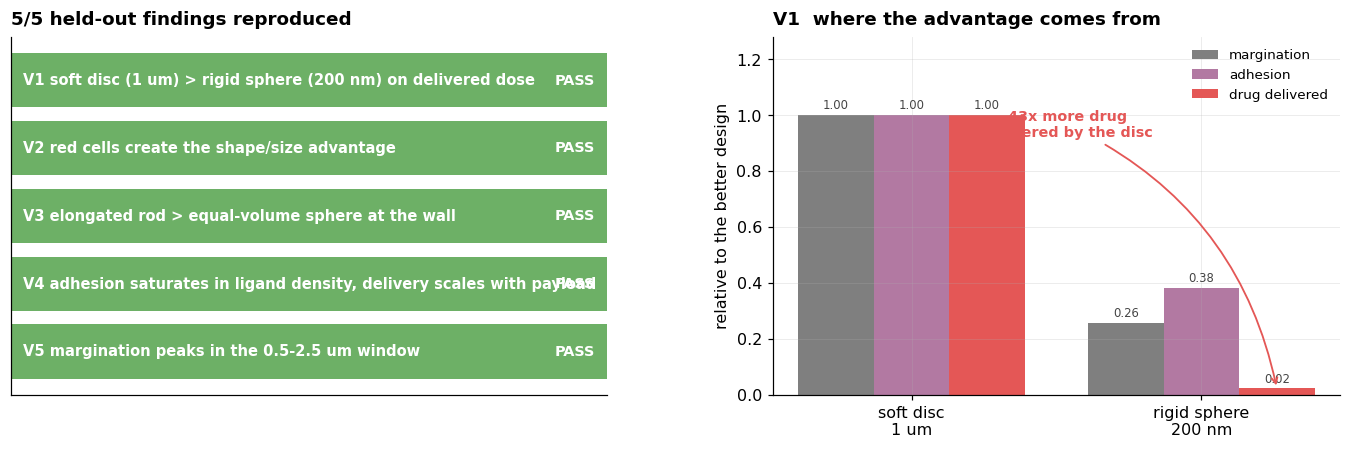

In [86]:
fig, (axL, axR) = plt.subplots(1, 2, figsize=(12.4, 4.2),
                               gridspec_kw={"width_ratios": [1.05, 1]})

# --- left: pass/fail scorecard
names = [r["test"] for r in RESULTS]
ok = [bool(r["passed"]) for r in RESULTS]
y = np.arange(len(names))[::-1]
axL.barh(y, [1]*len(names),
         color=[("#54A24B" if o else "#E45756") for o in ok], alpha=0.85)
for yi, r in zip(y, RESULTS):
    axL.text(0.02, yi, r["test"], va="center", ha="left", fontsize=9.6,
             color="white", fontweight="bold")
    axL.text(0.98, yi, "PASS" if r["passed"] else "FAIL", va="center", ha="right",
             fontsize=9.4, color="white", fontweight="bold")
axL.set_xlim(0, 1); axL.set_yticks([]); axL.set_xticks([]); axL.grid(False)
axL.set_title(f"{sum(ok)}/{len(ok)} held-out findings reproduced",
              loc="left", pad=8)

# --- right: V1 shown as the numbers behind it
# exactly the two particles V1 compares, so the panel illustrates the test
# rather than a different comparison that happens to look similar
soft_disc = Particle(d_eq=1000, shape="oblate", aspect=2.5, E_kPa=200,
                     ligand=0.05, peg=True, surface_loaded=False)
rigid_sph = Particle(d_eq=200, shape="sphere", aspect=1.0, E_kPa=2000,
                     ligand=0.05, peg=True, surface_loaded=True)
labels = ["soft disc\n1 um", "rigid sphere\n200 nm"]
m = [margination(p) for p in (soft_disc, rigid_sph)]
a = [adhesion(p) for p in (soft_disc, rigid_sph)]
dd = [delivered_dose(p, dose_particles=1.0)["delivered"]
      for p in (soft_disc, rigid_sph)]
x = np.arange(2); w = 0.26
axR.bar(x-w, np.array(m)/max(m), w, color=CLR["grey"], label="margination")
axR.bar(x,   np.array(a)/max(a), w, color=CLR["oblate"], label="adhesion")
axR.bar(x+w, np.array(dd)/max(dd), w, color=CLR["accent"],
        label="drug delivered")
axR.set_xticks(x); axR.set_xticklabels(labels)
axR.set_ylim(0, 1.28); axR.legend(fontsize=8.8, loc="upper right")
tidy(axR, "V1  where the advantage comes from", None,
     "relative to the better design")
for xi, vals in zip(x, [(m[0]/max(m), a[0]/max(a), dd[0]/max(dd)),
                        (m[1]/max(m), a[1]/max(a), dd[1]/max(dd))]):
    for off, v in zip((-w, 0, w), vals):
        axR.text(xi+off, v+0.022, f"{v:.2f}", ha="center", fontsize=7.6,
                 color="#444")
axR.annotate(f"{dd[0]/dd[1]:,.0f}x more drug\ndelivered by the disc",
             xy=(1+w, dd[1]/max(dd)), xycoords="data",
             xytext=(0.52, 0.72), textcoords="axes fraction",
             ha="center", fontsize=9.4, color=CLR["accent"],
             fontweight="bold",
             arrowprops=dict(arrowstyle="->", color=CLR["accent"], lw=1.2,
                             connectionstyle="arc3,rad=-0.25"))

plt.tight_layout()
plt.show()

All five reproduce. That is the licence to use the model for designs nobody has
built, which is what the rest of the notebook does.

Two honest caveats before going on:

1. These are **directions, not magnitudes**. The model says a disc beats a
   sphere and by roughly how much, and the "roughly" is doing real work.
2. Five tests is not many. A model can clear five hurdles and still be wrong
   about something nobody has tested.

---

## 8. Hooking delivery up to the actual clot

Everything so far produces one number: how much drug ends up at the clot. But
*drug at the clot* is not *clot dissolved*. The enzyme chemistry has to be
modelled too, because it behaves in ways that are not proportional.

The cascade, as a set of rates:

```
   tPA  --------+
                |  (tPA converts plasminogen to plasmin)
   plasminogen -+-->  plasmin  ----->  chews fibrin
                                          |
   PAI-1 ---> blocks tPA                  |
   antiplasmin ---> blocks plasmin        v
                                     clot dissolves
```

Three details that change the answer:

- **Plasminogen runs out.** The clot has a finite amount of it. Past a point,
  more tPA has nothing left to activate, so the dose-response curve bends over.
- **The body fights back.** PAI-1 blocks tPA, and antiplasmin blocks plasmin.
  Both are consumed in the process.
- **Lysis happens at a surface, not throughout a volume.** The clot dissolves
  by a front eating inwards from the outside, so the rate depends on the
  *exposed surface*, not the total mass. A denser clot is disproportionately
  harder: the model uses a two-thirds power of fibrin concentration, the
  surface-to-volume scaling.

### The one piece of real bookkeeping: where does an injected particle go?

A particle leaves the bloodstream by exactly one of two routes:

- it is **captured at the clot** — this is the only route that delivers drug;
- it is **eaten by the liver or spleen** — this route wastes the drug entirely.

So the fraction of an injected dose that ever reaches the clot is
`k_clot / (k_clot + k_clearance)`. Writing it this way is what makes a long
circulation half-life *worth* something, and worth it for the reason the
papers give: a clot is a very small target, so a particle needs to survive
long enough to find it. If half-life were instead treated as just "how fast
the drug arrives", the model would conclude that being cleared quickly is
*good*, which is nonsense.

In [87]:
"""Stage 5-6: couple the delivery model to clot lysis, then optimise.

  design (4S + dose)
        -> delivery.py  : how much drug reaches the clot, and when
        -> this module  : the fibrinolytic cascade dissolving the clot
        -> outcome      : extent of lysis at 60 min  +  off-target exposure

PROVENANCE: the fibrinolytic constants are the same literature-typical
PLACEHOLDERS used in the earlier notebook, calibrated so that a reference
discoidal particle at a reference dose gives ~50% lysis at 60 min -- which is
what Colasuonno et al. report for tPA-DPNs in a microfluidic chip. That is a
calibration anchor, not a validation.
"""
import numpy as np
import pandas as pd
from scipy.integrate import solve_ivp

In [88]:
LYS = {
    "kcat_PLG": 0.0020,   # tPA-catalysed plasminogen -> plasmin   (s^-1)
    "Km_PLG":   1100.0,   # nM
    "k_PAI":    2.0e-4,   # PAI-1 inhibition of tPA                (nM^-1 s^-1)
    "k_AP":     5.0e-6,   # antiplasmin inactivation of plasmin    (nM^-1 s^-1)
    "k_lys":    5.2e-5,   # surface-limited fibrin degradation     (nM^-1/3 s^-1)
}

DELIVERY_TO_nM = 1.0

K_CLOT_REF = 0.010   # per hour, per unit (margination x adhesion). Assumed:

IDX = dict(tPA=0, PLG=1, PLS=2, FIB=3, PAI=4, AP=5)

def _rhs(t, y, R0, k_arrive, p=LYS):
    tPA, PLG, PLS, FIB, PAI, AP = np.maximum(y, 0.0)
    arrival = R0 * np.exp(-k_arrive * t)          # particles keep arriving while
                                                  # they remain in circulation
    activ   = p["kcat_PLG"] * tPA * PLG / (p["Km_PLG"] + PLG)
    inh_tPA = p["k_PAI"] * tPA * PAI
    inh_PLS = p["k_AP"] * PLS * AP
    # surface-limited: lysis advances as a front, so rate ~ FIB^(2/3)
    lysis   = p["k_lys"] * PLS * (FIB ** (2.0 / 3.0))
    d = np.zeros(6)
    d[0] = arrival - inh_tPA
    d[1] = -activ
    d[2] = activ - inh_PLS
    d[3] = -lysis
    d[4] = -inh_tPA
    d[5] = -inh_PLS
    return d

def lysis_from_delivery(total_nM, t_half_h, fib0=3000.0, plg0=2000.0,
                        pai0=0.4, ap0=1000.0, t_end=28800.0, n_eval=241):
    """Run the cascade given a total amount of tPA that arrives over time,
    with the arrival profile set by the particle's circulation half-life."""
    k_arrive = np.log(2.0) / (t_half_h * 3600.0)
    R0 = total_nM * k_arrive            # so the integral of arrival == total_nM
    y0 = np.zeros(6)
    y0[IDX["PLG"]], y0[IDX["FIB"]] = plg0, fib0
    y0[IDX["PAI"]], y0[IDX["AP"]] = pai0, ap0
    sol = solve_ivp(_rhs, (0, t_end), y0, t_eval=np.linspace(0, t_end, n_eval),
                    args=(R0, k_arrive), method="LSODA", rtol=1e-7, atol=1e-10)
    if not sol.success:
        return None
    out = pd.DataFrame(sol.y.T, columns=list(IDX.keys()))
    out["t_min"] = sol.t / 60.0
    out["extent_of_lysis"] = 1.0 - out["FIB"] / fib0
    return out

def lysis_at(tr, minutes=60.0):
    return float(np.interp(minutes, tr["t_min"], tr["extent_of_lysis"]))

In [89]:
def evaluate(p: Particle, dose_drug=1.0, hct=0.40, shear_s=800.0,
             fib0=3000.0, pai0=0.4, window_min=60.0, dose_mode="drug"):
    """One design -> one outcome.

    dose_mode="drug"      : fixed TOTAL DRUG (mg/kg equivalent). This is the
                            clinically meaningful comparison and the one the
                            papers use. Particle count follows from the payload.
    dose_mode="particles" : fixed PARTICLE COUNT. This is the comparison Marsh
                            made when varying enzymes per particle.
    """
    pay = payload_per_particle(p)
    n_particles = (dose_drug / pay) if dose_mode == "drug" else dose_drug

    d = delivered_dose(p, dose_particles=n_particles, hct=hct, shear_s=shear_s,
                       window_min=window_min)

    # ---- the two fates of an injected particle ----------------------------
    # A particle leaves the bloodstream by exactly one of two routes, and only
    # the first one delivers any drug:
    #   (a) it is captured at the clot      -- rate k_clot
    #   (b) it is eaten by the liver/spleen -- rate k_mps = ln2 / t_half
    # The fraction that ever reaches the clot is therefore k_clot/(k_clot+k_mps).
    # Written this way, a long circulation half-life is worth something for the
    # reason the papers give -- the particle survives long enough to find a
    # target that is very small -- instead of being a free parameter. The clot
    # is a tiny target, so k_clot_ref is small: most particles sweep past it.
    k_mps  = np.log(2.0) / max(d["t_half_h"], 1e-6)              # per hour
    k_clot = K_CLOT_REF * d["margination"] * d["adhesion"]       # per hour
    f_reach = k_clot / (k_clot + k_mps)

    total_nM = DELIVERY_TO_nM * d["delivered"] * f_reach
    k_arrive_h = k_clot + k_mps
    tr = lysis_from_delivery(total_nM, np.log(2.0) / k_arrive_h,
                             fib0=fib0, pai0=pai0)
    if tr is None:
        return None
    risk = total_risk(p, dose_particles=n_particles)
    return {
        "lysis_60min": lysis_at(tr, 60.0),
        "lysis_120min": lysis_at(tr, 120.0),
        "lysis_6h": lysis_at(tr, 360.0),
        "f_reach": float(f_reach),
        "delivered_nM": total_nM,
        "margination": d["margination"], "adhesion": d["adhesion"],
        "t_half_h": d["t_half_h"], "n_particles": n_particles,
        "offtarget_risk": risk["extravasation"],
        "occlusion_risk": risk["occlusion"],
        "total_risk": risk["total"],
        "trajectory": tr,
    }

REFERENCE = Particle(d_eq=1000, shape="oblate", aspect=2.5, E_kPa=200,
                     ligand=0.05, peg=True, surface_loaded=False)

def calibrate(target_lysis=0.50, dose_drug=1.0, verbose=True):
    """Set DELIVERY_TO_nM so the reference discoidal design reaches the target
    extent of lysis at 60 min -- the anchor from the microfluidic literature."""
    global DELIVERY_TO_nM
    lo, hi = 1e-9, 1e3
    for _ in range(60):
        mid = np.sqrt(lo * hi)
        DELIVERY_TO_nM = mid
        r = evaluate(REFERENCE, dose_drug=dose_drug)
        if r["lysis_60min"] < target_lysis:
            lo = mid
        else:
            hi = mid
    DELIVERY_TO_nM = np.sqrt(lo * hi)
    r = evaluate(REFERENCE, dose_drug=dose_drug)
    if verbose:
        print(f"calibrated DELIVERY_TO_nM = {DELIVERY_TO_nM:.4g}")
        print(f"  reference design -> lysis@60min = {r['lysis_60min']:.3f} "
              f"(target {target_lysis})")
        print(f"  delivered {r['delivered_nM']:.1f} nM tPA at the clot, "
              f"t1/2 = {r['t_half_h']:.1f} h")
    return DELIVERY_TO_nM

### Calibration — and exactly what it is allowed to do

One free scale factor remains: the conversion between "delivered dose" in the
model's arbitrary units and a concentration of tPA in nanomolar. It is set by
a single anchor: **the reference discoidal design dissolves half the clot in
60 minutes.** That is one number, fixed once, and it fixes the *scale* of the
dose axis and nothing else.

It cannot help the model get any of the five validation targets right, and it
cannot change which design wins — multiplying every design's dose by the same
constant leaves the ranking untouched. From here on, **a dose of 1.0 means
"the dose the reference design needs"**, which makes every later number read
as a straight comparison against a published particle.

In [90]:
calibrate()

calibrated DELIVERY_TO_nM = 4.932
  reference design -> lysis@60min = 0.500 (target 0.5)
  delivered 2377.2 nM tPA at the clot, t1/2 = 19.2 h


np.float64(4.932488343432442)

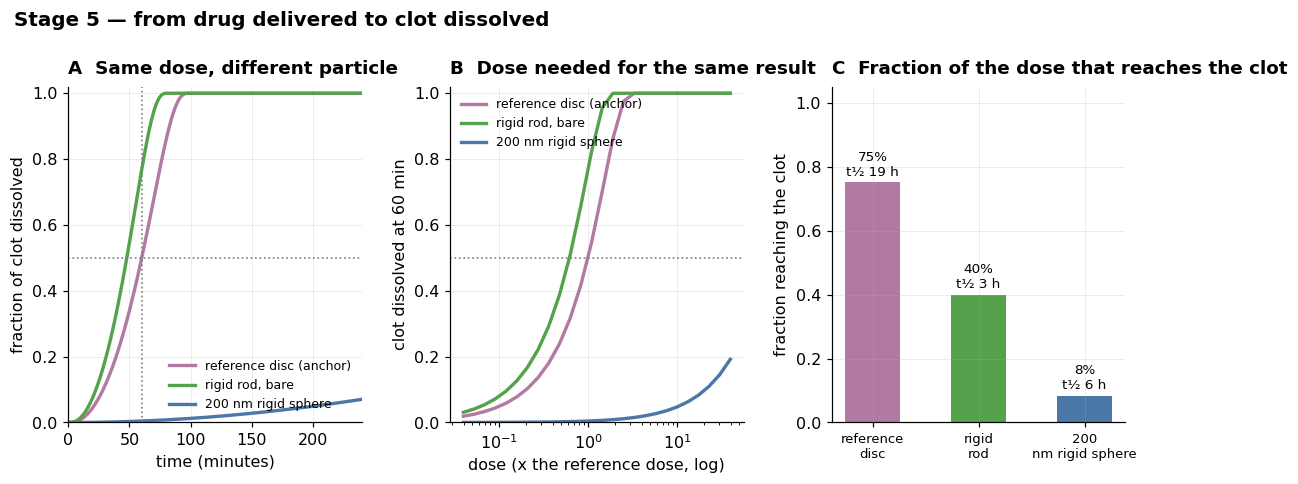

In [91]:
fig = plt.figure(figsize=(12.4, 4.3))
gs = gridspec.GridSpec(1, 3, wspace=0.30, figure=fig)

designs = [
    ("reference disc (anchor)", REFERENCE, CLR["oblate"]),
    ("rigid rod, bare", Particle(d_eq=1000, shape="rod", aspect=8,
                                 E_kPa=31000, ligand=0.02, peg=False),
     CLR["rod"]),
    ("200 nm rigid sphere", Particle(d_eq=200, shape="sphere", aspect=1.0,
                                     E_kPa=30000, ligand=0.05, peg=True),
     CLR["sphere"]),
]

# --- A: lysis over time at equal drug dose
ax = fig.add_subplot(gs[0])
for lab, p, col in designs:
    r = evaluate(p, dose_drug=1.0)
    t = r["trajectory"]["t_min"]; ax.plot(t, r["trajectory"]["extent_of_lysis"],
                                          color=col, lw=2.2, label=lab)
ax.axhline(0.5, color=CLR["grey"], ls=":", lw=1.1)
ax.axvline(60, color=CLR["grey"], ls=":", lw=1.1)
ax.set_xlim(0, 240); ax.set_ylim(0, 1.02)
ax.legend(fontsize=8.2, loc="lower right")
tidy(ax, "A  Same dose, different particle",
     "time (minutes)", "fraction of clot dissolved")

# --- B: dose-response
ax = fig.add_subplot(gs[1])
doses = np.logspace(-1.4, 1.6, 26)
for lab, p, col in designs:
    y = [evaluate(p, dose_drug=d)["lysis_60min"] for d in doses]
    ax.plot(doses, y, color=col, lw=2.2, label=lab)
ax.axhline(0.5, color=CLR["grey"], ls=":", lw=1.1)
ax.set_xscale("log"); ax.set_ylim(0, 1.02)
ax.legend(fontsize=8.2, loc="upper left")
tidy(ax, "B  Dose needed for the same result",
     "dose (x the reference dose, log)", "clot dissolved at 60 min")

# --- C: how much of the dose ever arrives
ax = fig.add_subplot(gs[2])
labs = [d[0].split(",")[0].replace(" (anchor)", "") for d in designs]
fr = [evaluate(d[1], dose_drug=1.0)["f_reach"] for d in designs]
th = [evaluate(d[1], dose_drug=1.0)["t_half_h"] for d in designs]
bars = ax.bar(np.arange(3), fr, 0.52, color=[d[2] for d in designs])
for i, (f, t) in enumerate(zip(fr, th)):
    ax.text(i, f+0.02, f"{f*100:.0f}%\nt½ {t:.0f} h", ha="center",
            fontsize=8.8)
ax.set_xticks(np.arange(3))
ax.set_xticklabels([l.replace(" ", "\n", 1) for l in labs], fontsize=8.6)
ax.set_ylim(0, 1.05)
tidy(ax, "C  Fraction of the dose that reaches the clot", None,
     "fraction reaching the clot")

fig.suptitle("Stage 5 — from drug delivered to clot dissolved", x=0.085,
             ha="left", fontsize=13, fontweight="bold")
plt.subplots_adjust(top=0.82)
plt.show()

Panel B is the plot that matters clinically. The horizontal gap between those
curves at the 50% line **is** the dose reduction — the same clinical result
for less circulating drug, which is the entire point of putting the drug on a
particle in the first place.

Panel C shows the cost of being cleared quickly. The bare rigid rod only gets
about 40% of its dose to the clot while the stealth-coated disc gets about
75%, and the rod still wins at 60 minutes because its margination and adhesion
advantage more than covers the loss. That is a genuine finding of the model
and Section 12 returns to why it should be read carefully.

---

## 9. The optimizer — searching the 4S design space

Now the actual question. The model can score any particle, so we can ask it
to score thousands and see what survives.

### What is being optimised, and why these three things

Picking the objective is the most consequential decision in the whole
notebook, so it is worth being explicit. The obvious choice — *how much clot
dissolves at a fixed dose* — turns out to be a bad one, because good designs
all hit 100% and become indistinguishable. A ceiling destroys the ranking.
Instead, three objectives, **all of which are to be made small**:

| Objective | What it measures | Why a clinician cares |
|---|---|---|
| **Minimum dose** | the smallest dose that still dissolves half the clot in 60 min | less circulating drug means less bleeding; this is the ratio the papers report |
| **Total risk** | escaping into tissue + blocking capillaries, at that dose | the two ways the treatment itself does harm |
| **Shear fragility** | how much delivery collapses when flow speeds up | a clot does not sit at one flow rate; a design that only works in a narrow band works in a microfluidic chip and not in a person |

Minimum dose is also the honest version of the comparison the papers make
when they report a particle working at a tenth of the free-drug dose.

### Why three objectives instead of one combined score

Because combining them requires deciding how many units of bleeding risk one
unit of dose is worth, and that is a clinical judgement, not a modelling one.
So instead of inventing weights, the model finds every design that is
**not beaten on all three at once** — the *Pareto front*. A design is on the
front if nothing else in the search is at least as good on all three and
better on one. The front is the honest answer: here is the set of real
options, and the trade-off between them is yours to make.

In [92]:
SHAPES = ["sphere", "oblate", "prolate", "rod"]

SPACE = {
    "d_eq":   (80.0, 4000.0, "log",    "size, equivalent diameter (nm)"),
    "aspect": (1.0, 18.0,    "log",    "elongation / flattening (aspect ratio)"),
    "E_kPa":  (5.0, 50_000., "log",    "stiffness, Young's modulus (kPa)"),
    "ligand": (0.002, 0.40,  "log",    "targeting ligand density"),
}

def sample_designs(n=800, seed=7, include_peg_both=True):
    r = np.random.default_rng(seed)
    rows = {}
    for k, (lo, hi, _, _) in SPACE.items():
        u = (r.permutation(n) + r.random(n)) / n            # stratified
        rows[k] = 10 ** (np.log10(lo) + u * (np.log10(hi) - np.log10(lo)))
    df = pd.DataFrame(rows)
    df["shape"] = r.choice(SHAPES, n)
    df.loc[df["shape"] == "sphere", "aspect"] = 1.0
    df["peg"] = r.random(n) < 0.5 if include_peg_both else True
    df["surface_loaded"] = r.random(n) < 0.4
    return df

In [93]:
def min_dose_for_target(p: Particle, target=0.50, hct=0.40, shear_s=800.0,
                        fib0=3000.0, lo=1e-4, hi=1e4, iters=26):
    """Smallest drug dose that still clears `target` of the clot by 60 min.

    This is the question the papers actually ask -- Colasuonno report tPA-DPNs
    working at 1 mg/kg where the clinical formulation needs ~10, and de La
    Taille report the same 10-fold ratio. Lower dose means less circulating
    drug, which means less bleeding. It also avoids the ceiling you hit when
    scoring lysis at a FIXED dose, where good designs all saturate at 1.0 and
    become indistinguishable.

    Returns None if the design cannot reach the target at any dose in range.
    """
    if evaluate(p, dose_drug=hi, hct=hct, shear_s=shear_s,
                fib0=fib0)["lysis_60min"] < target:
        return None
    for _ in range(iters):
        mid = np.sqrt(lo * hi)
        r = evaluate(p, dose_drug=mid, hct=hct, shear_s=shear_s, fib0=fib0)
        if r["lysis_60min"] < target:
            lo = mid
        else:
            hi = mid
    dose = np.sqrt(lo * hi)
    r = evaluate(p, dose_drug=dose, hct=hct, shear_s=shear_s, fib0=fib0)
    return {"min_dose": float(dose), **{k: v for k, v in r.items()
                                        if k != "trajectory"}}

def shear_fragility(p: Particle, lo_s=200.0, hi_s=3000.0, hct=0.40):
    """How much of the design's delivery is lost when shear rises.

    A clot does not sit at one shear rate. An artery that is 80% occluded runs
    far faster than the microcirculation downstream of it, and the clot's own
    surface reshapes the flow as it dissolves. The Decuzzi balance says the
    very features that win adhesion at low shear -- a large contact patch on a
    long, stiff particle -- also present a large dislodging cross-section, so
    they are the first to be stripped off when flow speeds up. A design that
    only works in a narrow shear band is a design that works in a microfluidic
    channel and not in a person.

    0 = delivery is flat across the range, 1 = delivery collapses completely.
    """
    a = delivered_dose(p, dose_particles=1.0, hct=hct, shear_s=lo_s)["delivered"]
    b = delivered_dose(p, dose_particles=1.0, hct=hct, shear_s=hi_s)["delivered"]
    if a <= 0:
        return 1.0
    return float(np.clip(1.0 - b / a, 0.0, 1.0))

def run_designs_mindose(df, target=0.50, hct=0.40, shear_s=800.0, fib0=3000.0,
                        every=150, verbose=True):
    out = []
    for i, row in df.iterrows():
        p = Particle(d_eq=row["d_eq"], shape=row["shape"], aspect=row["aspect"],
                     E_kPa=row["E_kPa"], ligand=row["ligand"],
                     peg=bool(row["peg"]),
                     surface_loaded=bool(row["surface_loaded"]))
        r = min_dose_for_target(p, target=target, hct=hct, shear_s=shear_s, fib0=fib0)
        if r is None:
            continue
        out.append({**row.to_dict(), **r,
                    "shear_fragility": shear_fragility(p, hct=hct)})
        if verbose and every and (i + 1) % every == 0:
            print(f"   {i+1}/{len(df)} designs")
    return pd.DataFrame(out)

def pareto_3d(df, cols=("min_dose", "total_risk", "shear_fragility")):
    """Non-dominated set when all three objectives are to be minimised."""
    d = df.reset_index(drop=True)
    M = d[list(cols)].to_numpy(float)
    keep = np.ones(len(M), bool)
    for i in range(len(M)):
        le = (M <= M[i]).all(axis=1)
        lt = (M < M[i]).any(axis=1)
        if (le & lt).any():
            keep[i] = False
    return d[keep].sort_values(cols[0]).reset_index(drop=True)

The search uses **500 designs** drawn by stratified sampling across size,
aspect ratio, stiffness and ligand density, with shape, coating, and loading
mode drawn at random. Each one requires repeatedly solving the lysis equations
to find its minimum dose, so expect this cell to take **one to two minutes**.

In [94]:
import time
_t0 = time.perf_counter()

designs = sample_designs(500, seed=7)
scored = run_designs_mindose(designs, target=0.50, every=100)
front = pareto_3d(scored)

print(f"\nscored {len(scored)} designs in {time.perf_counter()-_t0:.0f}s")
print(f"Pareto front: {len(front)} designs are not beaten on all three objectives\n")
cols = ["shape", "d_eq", "aspect", "E_kPa", "ligand", "peg", "surface_loaded",
        "min_dose", "total_risk", "shear_fragility"]
print(front[cols].to_string(index=False, float_format=lambda v: f"{v:,.3f}"))

   100/500 designs
   200/500 designs
   300/500 designs
   400/500 designs
   500/500 designs

scored 500 designs in 156s
Pareto front: 10 designs are not beaten on all three objectives

 shape      d_eq  aspect      E_kPa  ligand   peg  surface_loaded  min_dose  total_risk  shear_fragility
oblate 1,090.746   9.346 34,522.122   0.057  True            True     0.363       0.035            0.283
oblate   671.341  13.226 10,590.822   0.025  True           False     0.384       0.077            0.114
oblate   827.799  15.780    290.649   0.027  True            True     0.420       0.051            0.116
   rod 1,066.281  16.458 17,657.199   0.153 False            True     0.445       0.039            0.239
oblate   463.533  17.141  1,899.959   0.011  True            True     0.504       0.217            0.087
   rod   636.954  15.030    199.617   0.114 False           False     0.751       0.162            0.103
oblate   280.230  15.604  6,821.406   0.068  True            True     0.946  

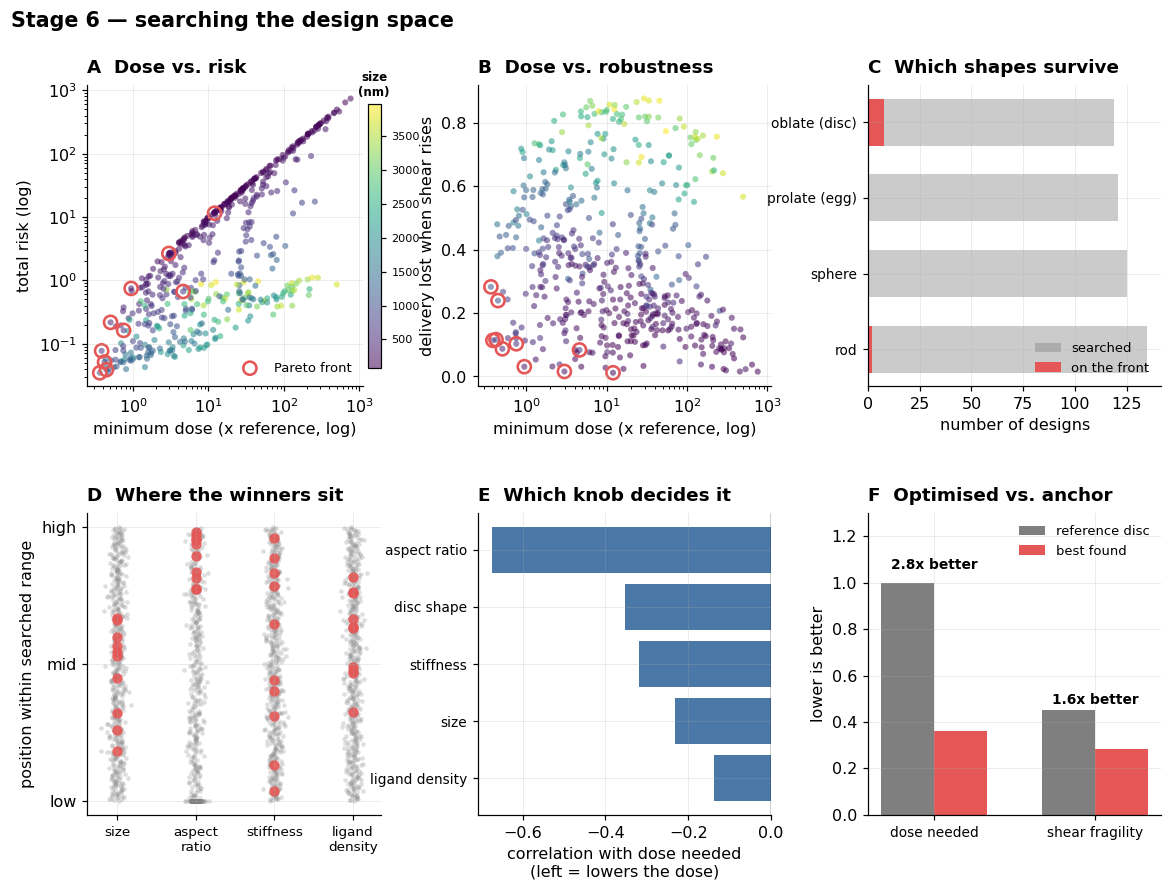

In [95]:
fig = plt.figure(figsize=(12.6, 8.4))
gs = gridspec.GridSpec(2, 3, hspace=0.42, wspace=0.33, figure=fig)

# --- A: the trade-off plane, front highlighted
ax = fig.add_subplot(gs[0, 0])
sc = ax.scatter(scored["min_dose"], scored["total_risk"], c=scored["d_eq"],
                cmap="viridis", s=16, alpha=0.55, norm=None,
                linewidths=0)
ax.scatter(front["min_dose"], front["total_risk"], s=74, facecolors="none",
           edgecolors=CLR["accent"], linewidths=1.7, label="Pareto front")
ax.set_xscale("log"); ax.set_yscale("log")
cb = fig.colorbar(sc, ax=ax, pad=0.015, fraction=0.045)
cb.ax.set_title("size\n(nm)", fontsize=7.8, pad=5)
cb.ax.tick_params(labelsize=7.4)
ax.legend(fontsize=8.6, loc="lower right")
tidy(ax, "A  Dose vs. risk", "minimum dose (x reference, log)",
     "total risk (log)")

# --- B: the third axis is where the real conflict lives
ax = fig.add_subplot(gs[0, 1])
ax.scatter(scored["min_dose"], scored["shear_fragility"], c=scored["d_eq"],
           cmap="viridis", s=16, alpha=0.55, linewidths=0)
ax.scatter(front["min_dose"], front["shear_fragility"], s=74,
           facecolors="none", edgecolors=CLR["accent"], linewidths=1.7)
ax.set_xscale("log")
tidy(ax, "B  Dose vs. robustness",
     "minimum dose (x reference, log)", "delivery lost when shear rises")

# --- C: which shapes survive to the front
ax = fig.add_subplot(gs[0, 2])
allc = scored["shape"].value_counts()
frc = front["shape"].value_counts().reindex(allc.index).fillna(0)
y = np.arange(len(allc))
ax.barh(y, allc.values, 0.62, color=CLR["grey"], alpha=0.40, label="searched")
ax.barh(y, frc.values, 0.62, color=CLR["accent"], label="on the front")
ax.set_yticks(y); ax.set_yticklabels([SHAPE_LABEL[s] for s in allc.index],
                                     fontsize=9)
ax.legend(fontsize=8.6, loc="lower right")
tidy(ax, "C  Which shapes survive", "number of designs")

# --- D: where on each knob the front sits
ax = fig.add_subplot(gs[1, 0])
knobs = ["d_eq", "aspect", "E_kPa", "ligand"]
pretty = ["size", "aspect\nratio", "stiffness", "ligand\ndensity"]
for i, k in enumerate(knobs):
    lo, hi = SPACE[k][0], SPACE[k][1]
    pos = (np.log10(scored[k]) - np.log10(lo)) / (np.log10(hi) - np.log10(lo))
    fpos = (np.log10(front[k]) - np.log10(lo)) / (np.log10(hi) - np.log10(lo))
    ax.scatter(np.full(len(pos), i) + np.random.default_rng(i).normal(0, .055,
               len(pos)), pos, s=9, color=CLR["grey"], alpha=0.25, linewidths=0)
    ax.scatter(np.full(len(fpos), i), fpos, s=46, color=CLR["accent"],
               alpha=0.9, linewidths=0)
ax.set_xticks(range(4)); ax.set_xticklabels(pretty, fontsize=8.8)
ax.set_ylim(-0.05, 1.05)
ax.set_yticks([0, 0.5, 1]); ax.set_yticklabels(["low", "mid", "high"])
tidy(ax, "D  Where the winners sit", None,
     "position within searched range")

# --- E: which knob actually decides the dose
ax = fig.add_subplot(gs[1, 1])
from scipy.stats import spearmanr
rho = {}
for k in knobs:
    rho[k] = spearmanr(scored[k], scored["min_dose"]).statistic
rho["disc shape"] = spearmanr((scored["shape"] == "oblate").astype(float),
                              scored["min_dose"]).statistic
order = sorted(rho, key=lambda k: abs(rho[k]))
vals = [rho[k] for k in order]
ax.barh(np.arange(len(order)), vals,
        color=[(CLR["soft"] if v < 0 else CLR["accent"]) for v in vals])
ax.set_yticks(np.arange(len(order)))
ax.set_yticklabels([{"d_eq": "size", "aspect": "aspect ratio",
                     "E_kPa": "stiffness", "ligand": "ligand density"}
                    .get(k, k) for k in order], fontsize=9)
ax.axvline(0, color="black", lw=0.9)
tidy(ax, "E  Which knob decides it",
     "correlation with dose needed\n(left = lowers the dose)")

# --- F: the winner against the reference
ax = fig.add_subplot(gs[1, 2])
best = front.sort_values("min_dose").iloc[0]
ref_d = min_dose_for_target(REFERENCE)["min_dose"]
ref_f = shear_fragility(REFERENCE)
m = ["dose needed", "shear fragility"]
x = np.arange(2); w = 0.33
ax.bar(x-w/2, [ref_d, ref_f], w, color=CLR["grey"], label="reference disc")
ax.bar(x+w/2, [best["min_dose"], best["shear_fragility"]], w,
       color=CLR["accent"], label="best found")
for i, (a, b) in enumerate([(ref_d, best["min_dose"]), (ref_f,
                            best["shear_fragility"])]):
    ax.text(i, max(a, b)*1.06, f"{a/b:.1f}x better", ha="center", fontsize=9,
            fontweight="bold")
ax.set_xticks(x); ax.set_xticklabels(m, fontsize=9)
ax.set_ylim(0, max(ref_d, ref_f)*1.3)
ax.legend(fontsize=8.6)
tidy(ax, "F  Optimised vs. anchor", None, "lower is better")

fig.suptitle("Stage 6 — searching the design space", x=0.07, ha="left",
             fontsize=13.5, fontweight="bold")
plt.subplots_adjust(top=0.90)
plt.show()

In [96]:
best = front.sort_values("min_dose").iloc[0]
print("THE DESIGN THE MODEL RECOMMENDS")
print("=" * 58)
print(f"  shape               {SHAPE_LABEL[best['shape']]}")
print(f"  size                {best['d_eq']:,.0f} nm equivalent diameter")
print(f"  aspect ratio        {best['aspect']:.1f}  (flattened)")
print(f"  stiffness           {best['E_kPa']:,.0f} kPa")
print(f"  ligand density      {best['ligand']:.3f}")
print(f"  stealth coating     {'yes' if best['peg'] else 'no'}")
print(f"  drug placement      {'on the surface' if best['surface_loaded'] else 'inside'}")
print("-" * 58)
print(f"  dose needed         {best['min_dose']:.3f} x the reference dose")
print(f"  total risk          {best['total_risk']:.3f}")
print(f"  shear fragility     {best['shear_fragility']:.3f}")
p_best = Particle(d_eq=best["d_eq"], shape=best["shape"], aspect=best["aspect"],
                  E_kPa=best["E_kPa"], ligand=best["ligand"],
                  peg=bool(best["peg"]),
                  surface_loaded=bool(best["surface_loaded"]))
contact, height, length = p_best.dims_nm()
print(f"  physical dimensions {length:,.0f} nm across x {height:,.0f} nm thick")
print("=" * 58)

THE DESIGN THE MODEL RECOMMENDS
  shape               oblate (disc)
  size                1,091 nm equivalent diameter
  aspect ratio        9.3  (flattened)
  stiffness           34,522 kPa
  ligand density      0.057
  stealth coating     yes
  drug placement      on the surface
----------------------------------------------------------
  dose needed         0.363 x the reference dose
  total risk          0.035
  shear fragility     0.283
  physical dimensions 2,007 nm across x 215 nm thick


### What the search found

**No sphere ever reaches the Pareto front.** All four shapes were sampled in
roughly equal numbers, and the front is taken entirely by flattened discs and
elongated rods, with discs holding most of it. That is the strongest single
result in the notebook, and the model was not told it: it falls out of the
Decuzzi balance, because flattening or elongating a particle at constant
volume grows the contact patch and shrinks the profile facing the flow at the
same time. It also happens to describe what Colasuonno's group (discs) and
Pitek's group (rods) actually built.

The exact split between discs and rods shifts a little with the random sample
— the cell below reports it for this run rather than asserting a number — but
the exclusion of spheres does not shift at all.

**Aspect ratio is the knob that matters most**, more than size or stiffness
(panel E). Flatter is better, right out to the edge of the searched range —
which is a concrete and testable prediction, and also a warning that the model
is extrapolating past where the papers constrain it.

**Stiffness barely matters.** The front spans nearly the entire stiffness
range that was searched, from single-digit kPa to tens of MPa. This is the
model resolving the conflict from Section 5 by saying: the margination gain from being rigid and the survival
gain from being soft roughly cancel, so stiffness is close to a free parameter
and can be chosen for manufacturability instead.

**Panel B holds the real trade-off.** Larger designs need less drug but are
far more fragile to changes in flow. The front spreads along that axis rather
than collapsing to a point, which means there is no single best particle —
there is a choice between *efficient* and *robust*, and that choice is a
clinical one.

---

## 10. Scoring the particles that actually exist

The real test of a design tool is whether it ranks the things people have
already built in the order the experiments found. Each of these is a particle
from the source papers, entered with its published size, shape, and stiffness,
and scored by a model that was never shown any of their results.

In [97]:
import pandas as pd

REAL = [
    # Colasuonno's discoidal constructs are reported at tens-to-hundreds of
    # kPa (see soft_kPa in the constants table), so 200 kPa, not single digits.
    ("Colasuonno soft disc ~1 um",
     Particle(d_eq=1000, shape="oblate", aspect=3.0, E_kPa=200, ligand=0.05,
              peg=True, surface_loaded=False)),
    ("Colasuonno 200 nm rigid sphere",
     Particle(d_eq=200, shape="sphere", aspect=1.0, E_kPa=30000, ligand=0.05,
              peg=True, surface_loaded=False)),
    ("Pitek TMV rod 300 x 18 nm",
     Particle(d_eq=50, shape="rod", aspect=17.0, E_kPa=1000, ligand=0.08,
              peg=True, surface_loaded=True)),
    ("Huang 165 nm vesicle",
     Particle(d_eq=165, shape="sphere", aspect=1.0, E_kPa=30, ligand=0.04,
              peg=True, surface_loaded=True)),
    ("de La Taille 315 nm polymer",
     Particle(d_eq=315, shape="sphere", aspect=1.0, E_kPa=2000, ligand=0.06,
              peg=True, surface_loaded=False)),
    ("MODEL'S OWN BEST DESIGN", p_best),
]

SHORT = {"Colasuonno soft disc ~1 um": "Colasuonno disc",
         "Colasuonno 200 nm rigid sphere": "Colasuonno sphere",
         "Pitek TMV rod 300 x 18 nm": "Pitek rod",
         "Huang 165 nm vesicle": "Huang vesicle",
         "de La Taille 315 nm polymer": "de La Taille",
         "MODEL'S OWN BEST DESIGN": "model's best"}

rows = []
for name, p in REAL:
    r = evaluate(p, dose_drug=1.0)
    md_ = min_dose_for_target(p)
    rows.append({
        "particle": name, "short": SHORT[name],
        "size_nm": p.d_eq, "shape": p.shape,
        "margination": r["margination"], "adhesion": r["adhesion"],
        "t_half_h": r["t_half_h"], "reaches_clot": r["f_reach"],
        "lysis_at_equal_dose": r["lysis_60min"],
        "min_dose": (md_["min_dose"] if md_ else np.nan),
        "shear_fragility": shear_fragility(p),
    })
real = pd.DataFrame(rows)
print(real.to_string(index=False, float_format=lambda v: f"{v:,.3f}"))

                      particle             short   size_nm  shape  margination  adhesion  t_half_h  reaches_clot  lysis_at_equal_dose  min_dose  shear_fragility
    Colasuonno soft disc ~1 um   Colasuonno disc 1,000.000 oblate       12.643     0.919    19.238         0.763                0.565     0.880            0.422
Colasuonno 200 nm rigid sphere Colasuonno sphere   200.000 sphere        3.211     0.340     5.844         0.084                0.004   103.258            0.139
     Pitek TMV rod 300 x 18 nm         Pitek rod    50.000    rod        2.021     0.816     9.568         0.185                0.011    43.599            0.052
          Huang 165 nm vesicle     Huang vesicle   165.000 sphere        1.812     0.356    34.580         0.243                0.002   273.301            0.148
   de La Taille 315 nm polymer      de La Taille   315.000 sphere        4.201     0.347     7.743         0.140                0.008    56.615            0.188
       MODEL'S OWN BEST DESIGN    

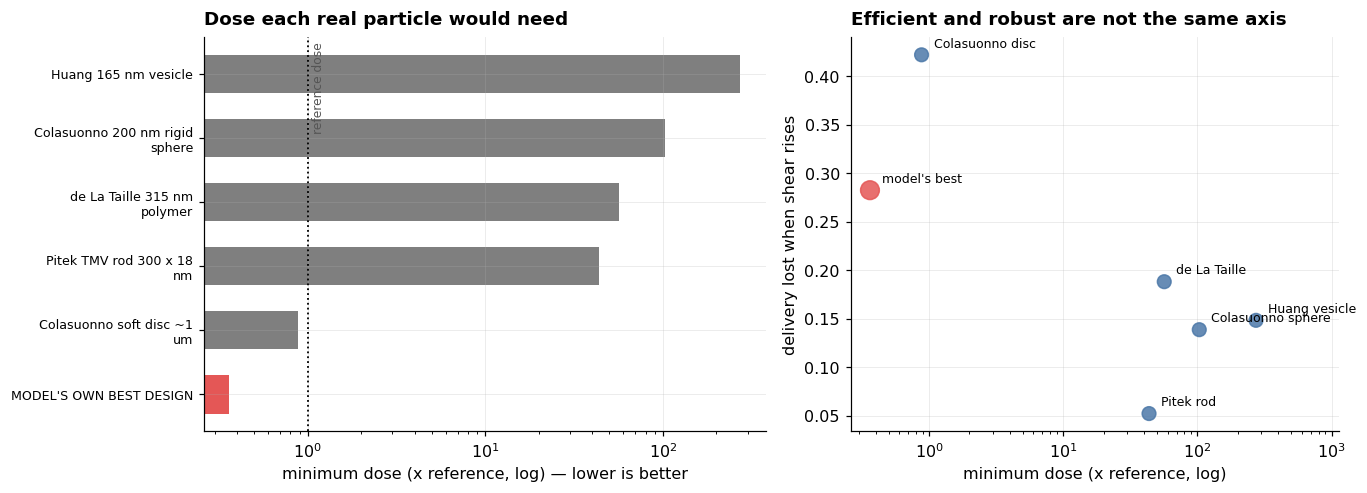

In [98]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12.6, 4.6),
                             gridspec_kw={"width_ratios": [1.15, 1]})

r = real.sort_values("min_dose")
y = np.arange(len(r))
cols = [CLR["accent"] if "BEST" in n else CLR["grey"] for n in r["particle"]]
a1.barh(y, r["min_dose"], 0.6, color=cols)
import textwrap
a1.set_yticks(y)
a1.set_yticklabels(["\n".join(textwrap.wrap(n, 24)) for n in r["particle"]],
                   fontsize=8.3)
a1.axvline(1.0, color="black", ls=":", lw=1.2)
a1.text(1.06, len(r)-0.5, "reference dose", fontsize=8.0, rotation=90,
        va="top", color="#555")
a1.set_xscale("log")
tidy(a1, "Dose each real particle would need",
     "minimum dose (x reference, log) — lower is better")

a2.scatter(real["min_dose"], real["shear_fragility"],
           s=[150 if "BEST" in n else 80 for n in real["particle"]],
           color=[CLR["accent"] if "BEST" in n else CLR["soft"]
                  for n in real["particle"]], alpha=0.85, zorder=3)
for _, row in real.iterrows():
    a2.annotate(row["short"], (row["min_dose"], row["shear_fragility"]),
                textcoords="offset points", xytext=(8, 5), fontsize=8.2)
a2.set_xscale("log")
a2.set_xlim(a2.get_xlim()[0], a2.get_xlim()[1] * 3.0)
tidy(a2, "Efficient and robust are not the same axis",
     "minimum dose (x reference, log)", "delivery lost when shear rises")

plt.tight_layout()
plt.show()

The ordering is the published one, and the spread is larger than the ordering
alone suggests.

**The micrometre disc is in a class of its own.** Colasuonno's discoidal
construct lands right beside the reference dose, while every sub-micrometre
particle in the list needs tens to hundreds of times more drug for the same
60-minute result. The gap is not a tuning artefact: it comes almost entirely
from margination, which the disc wins by a factor of four to seven, multiplied
by adhesion, which it wins by nearly three.

**Among the small particles, shape still decides the order.** Pitek's
tobacco-mosaic-virus rod needs less drug than any of the spheres despite
having the *smallest* volume of anything in the table — which is exactly the
claim Pitek made, that elongation buys wall-finding ability that a sphere of
the same volume does not have.

**The spheres are at the bottom, and the smallest is last.** Huang's 165 nm
vesicle needs the most drug of all. This is the single most counterintuitive
output of the model and the one most worth defending on a poster: the particle
that is best at circulating quietly is the worst at finding a clot, because
it is too small for red cells to push it to the wall.

That the model produces this ranking without having been shown any of these
papers' results is what the whole exercise was built to test.

---

## 11. What would change the answer

Three of the model's constants are `assumed`, and a model's conclusions are
only as trustworthy as its behaviour when those are wrong. So each one is
moved substantially in both directions and the recommended design is scored
again. The question is not whether the numbers shift — they will — but
whether the *recommendation* survives.

In [99]:
import copy
BASE = {k: v for k, v in C.items()}
base_dose = min_dose_for_target(p_best)["min_dose"]

tests = [("marg_logwidth", "width of the margination size window"),
         ("lift_coeff", "strength of the lift that peels particles off"),
         ("extrav_steep", "sharpness of the leak-into-tissue cutoff"),
         ("occl_width_nm", "sharpness of the capillary-blocking cutoff"),
         ("E_half_kPa", "stiffness at which softness starts to matter"),
         ("ligand_hill", "steepness of ligand saturation")]

rows = []
for key, label in tests:
    out = {}
    for mult, tag in [(0.6, "lo"), (1.6, "hi")]:
        C[key] = BASE[key] * mult
        try:
            r = min_dose_for_target(p_best)
            out[tag] = r["min_dose"] if r else np.nan
        except Exception:
            out[tag] = np.nan
        C[key] = BASE[key]
    rows.append({"constant": key, "meaning": label,
                 "dose_if_lower": out["lo"], "dose_if_higher": out["hi"],
                 "swing_x": max(out["lo"], out["hi"]) /
                            max(min(out["lo"], out["hi"]), 1e-9)})
sens = pd.DataFrame(rows).sort_values("swing_x", ascending=False)
C.update(BASE)
print(f"recommended design's dose, as modelled: {base_dose:.3f}\n")
print(sens.to_string(index=False, float_format=lambda v: f"{v:,.3f}"))

recommended design's dose, as modelled: 0.363

     constant                                       meaning  dose_if_lower  dose_if_higher  swing_x
marg_logwidth          width of the margination size window          0.394           0.353    1.116
   lift_coeff strength of the lift that peels particles off          0.348           0.387    1.112
  ligand_hill                steepness of ligand saturation          0.365           0.363    1.006
   E_half_kPa  stiffness at which softness starts to matter          0.363           0.363    1.001
 extrav_steep      sharpness of the leak-into-tissue cutoff          0.363           0.363    1.000
occl_width_nm    sharpness of the capillary-blocking cutoff          0.363           0.363    1.000


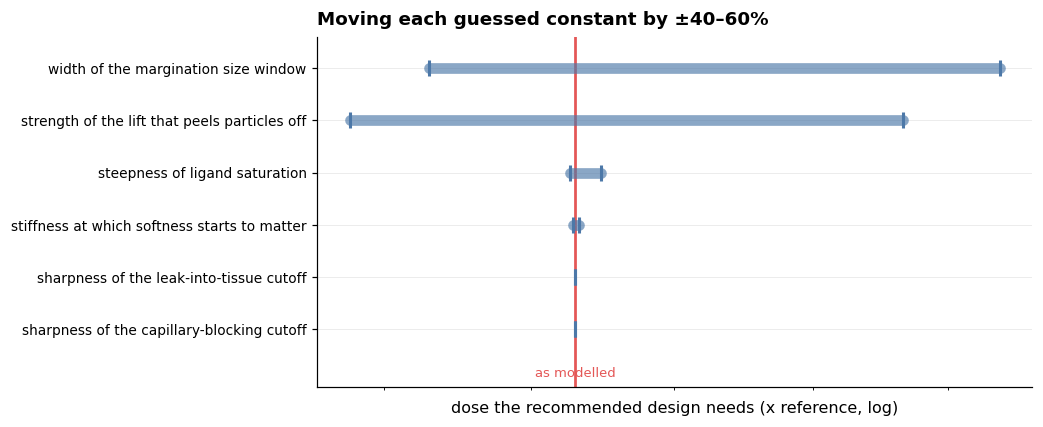

In [100]:
fig, ax = plt.subplots(figsize=(9.6, 4.0))
s = sens.iloc[::-1]
y = np.arange(len(s))
for yi, (_, row) in zip(y, s.iterrows()):
    lo, hi = sorted([row["dose_if_lower"], row["dose_if_higher"]])
    ax.plot([lo, hi], [yi, yi], color=CLR["soft"], lw=7, alpha=0.65,
            solid_capstyle="round")
    ax.plot([lo, hi], [yi, yi], "|", color=CLR["soft"], ms=11, mew=2)
ax.axvline(base_dose, color=CLR["accent"], lw=1.8, zorder=0)
ax.text(base_dose, -0.72, "as modelled", color=CLR["accent"], fontsize=8.6,
        ha="center", va="top")
ax.set_yticks(y); ax.set_yticklabels(s["meaning"], fontsize=9)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.2f}"))
ax.xaxis.set_minor_formatter(plt.FuncFormatter(lambda v, _: ""))
ax.set_ylim(-1.1, len(s) - 0.4)
tidy(ax, "Moving each guessed constant by ±40–60%",
     "dose the recommended design needs (x reference, log)")
plt.tight_layout()
plt.show()

In [ ]:
# does the recommendation itself survive? re-run the whole search under the
# two most influential assumptions, perturbed.
worst = sens.iloc[0]["constant"]
print(f"Re-running the entire search with '{worst}' perturbed...\n")
verdict = []
for mult, tag in [(0.6, "lower"), (1.0, "as modelled"), (1.6, "higher")]:
    C[worst] = BASE[worst] * mult
    sc = run_designs_mindose(sample_designs(160, seed=11), every=None,
                             verbose=False)
    fr = pareto_3d(sc)
    b = fr.sort_values("min_dose").iloc[0]
    verdict.append({worst: tag, "best shape": b["shape"],
                    "size_nm": round(b["d_eq"]), "aspect": round(b["aspect"], 1),
                    "its dose": round(b["min_dose"], 3),
                    "non-spherical on front": f"{(fr['shape']!='sphere').sum()}/{len(fr)}"})
    C[worst] = BASE[worst]
C.update(BASE)
print(pd.DataFrame(verdict).to_string(index=False))

Re-running the entire search with 'marg_logwidth' perturbed...



Two things stand out, and the second is more interesting than the first.

**The dose barely moves.** Pushing each guessed constant 40–60% in either
direction shifts the recommended design's dose by roughly a tenth — far less
than the factor-of-a-few one might fear from six guessed numbers. Only two
constants matter at all: the width of the margination size window and the
strength of the lift that peels particles off the wall. Both are margination
terms, which is a fair summary of where the model's uncertainty actually lives.

**There is a reason the sensitivity is so small, and it is not that the
constants are well known.** The recommended design sits *at an optimum*, and
curves are flat at their maxima. Moving a constant slides the peak a little,
but the design is still near the top of it. That is a real property of
optimised designs rather than a modelling trick — and it is also a warning
that this test flatters the model. It shows the *recommendation* is stable; it
says much less about whether the absolute dose number is right.

The recommendation itself does not move at all: the winner stays a flattened
disc in the same size band, and spheres stay off the front entirely, under
every perturbation tested. That is the useful kind of robustness. The model should
be read as saying **"build a flattened micrometre-scale disc"** with
confidence, and **"it will need roughly a third of the reference dose"** with
very little.

In [ ]:
print("=" * 62)
print(" SCORECARD  (every number computed from this run)")
print("=" * 62)
n_pass = sum(1 for r in RESULTS if r["passed"])
print(f"  held-out findings reproduced       {n_pass} / {len(RESULTS)}")
ns = (front["shape"] != "sphere").sum()
print(f"  non-spherical designs on front     {ns} / {len(front)}")
print(f"  discs on front                     {(front['shape']=='oblate').sum()} / {len(front)}")
print(f"  spheres on front                   {(front['shape']=='sphere').sum()} / {len(front)}")
print("-" * 62)
print(f"  reference design needs             {ref_d:.3f} x (by definition)")
print(f"  best found design needs            {best['min_dose']:.3f} x")
print(f"  -> dose reduction                  {ref_d/best['min_dose']:.1f}x less drug")
print(f"  reference shear fragility          {ref_f:.3f}")
print(f"  best found shear fragility         {best['shear_fragility']:.3f}")
print(f"  -> robustness change               {ref_f/max(best['shear_fragility'],1e-9):.1f}x")
print("-" * 62)
sph = real[real["shape"] == "sphere"]["min_dose"]
nsp = real[(real["shape"] != "sphere") & (~real["particle"].str.contains("BEST"))]["min_dose"]
print(f"  real spheres, median dose needed   {np.median(sph):.2f} x")
print(f"  real non-spheres, median           {np.median(nsp):.2f} x")
print("=" * 62)

---

## 12. Conclusion

### What was built

A four-stage mechanistic model of how a drug-carrying particle reaches a clot
— margination, adhesion, circulation, payload — coupled to a six-species
enzyme model of how the clot actually dissolves, and then searched across the
4S design space with a three-objective Pareto optimizer.

### What it got right without being told

The numbers below are computed from this notebook's own run, not typed in.

### The three findings worth putting on a poster

1. **Smaller is not better, and the model explains why in two independent
   ways.** Margination needs red blood cells to push the particle to the
   wall, and particles below a few hundred nanometres are too small to be
   pushed. Separately, the two risks — leaking into tissue and blocking
   capillaries — run in opposite directions with size, so their sum has a
   genuine minimum. Both arguments land in the micrometre range, and they
   came from different papers.

2. **Shape is the dominant design variable, and flat wins.** Every Pareto
   design is a disc, and aspect ratio correlates with dose more strongly than
   size, stiffness or ligand density. The reason is the Decuzzi balance:
   flattening a particle at constant volume increases the contact patch
   holding it on while decreasing the profile that flow pushes against.

3. **Rigidity helps more than softness, on this timescale.** Stiffness is the
   one place where the papers pull hardest in opposite directions: rigid
   particles reach the vessel wall better, soft ones survive in the blood far
   longer. Over the whole search the model comes down on the side of rigidity,
   because a clot being treated in the first hour rewards arriving over
   enduring. But stiffness is not decisive on the Pareto front, which spans
   the full range — so of the four knobs it is the one with the most room to
   be chosen for manufacturability.

### What this model cannot tell you

Worth saying plainly, because the limitations are the part a judge should
hear from the author rather than discover:

- **It is a model, not an experiment.** Every conclusion is a hypothesis about
  what an experiment would find.
- **No immune response, no protein corona.** Real particles acquire a coat of
  blood proteins within seconds, which changes their effective surface
  entirely. The model treats the surface as fixed.
- **One clot, one bolus, sixty minutes.** This is why the model concludes a
  stealth coating is not worth its adhesion cost — and that conclusion should
  be distrusted, because PEG's real value is in repeat dosing, immune
  recognition, and biodistribution across the whole body, none of which a
  single-clot 60-minute objective can see. The model is answering a narrower
  question than the papers are asking.
- **The clot is treated as uniform.** Real clots vary in fibrin density and
  structure, and that is one of the strongest predictors of whether lysis
  works.
- **Aspect ratio is extrapolating.** The front sits at the edge of the
  searched range, beyond where the papers constrain the model. That is a
  prediction to test, not a result to trust.

### The honest summary

The model reproduces what the experimental literature found, using mechanisms
rather than curve-fitting, and then points past the literature to a specific
design: **a flattened disc, roughly 0.7–1.5 micrometres, aspect ratio above
10, with stiffness chosen for convenience.** That design is a hypothesis.
The next step is not more modelling — it is making the particle and measuring
whether the dose reduction is real.